## 1. Data sources and initial cleaning

Load HAALSI source files and prepare initial respondent and neuro-examination data.

In [2]:
import pandas as pd

main = pd.read_csv("HAALSI_W1-3_Longitudinal_Dataset.csv")
neuro = pd.read_csv("HAALSI_DEMENTIA_Neuro_W2.csv")
resp = pd.read_csv("HAALSI_DEMENTIA_Respondent_W2.csv")

print("Conversion complete. The datasets have been saved as 'HAALSI_W1-3_Longitudinal_Dataset.csv', 'HAALSI_DEMENTIA_Neuro_W2.csv', and 'HAALSI_DEMENTIA_Respondent_W2.csv'.")

C:\Users\Wits student\AppData\Local\Temp\ipykernel_18280\1185814936.py:3: DtypeWarning: Columns (0: w1hhmemberage_11_, 1: w1hhmemberprimkey_37_, 2: w1hhmemberprimkey_38_, 3: w1hhmemberprimkey_39_, 4: w1hhmemberprimkey_36_, 5: w1hhmemberprimkey_35_, 6: w1hhmemberprimkey_31_, 7: w1hhmemberprimkey_32_, 8: w1hhmemberprimkey_33_, 9: w1hhmemberprimkey_34_, 10: w1hhmemberprimkey_40_, 11: w1hhmemberprimkey_41_, 12: w1hhmemberprimkey_42_, 13: w1hhmemberprimkey_43_, 14: w1hhmemberprimkey_45_, 15: w1hhmemberprimkey_30_, 16: w1hhmemberprimkey_17_, 17: w1hhmemberprimkey_18_, 18: w1hhmemberprimkey_19_, 19: w1hhmemberprimkey_20_, 20: w1hhmemberprimkey_26_, 21: w1hhmemberprimkey_27_, 22: w1hhmemberprimkey_28_, 23: w1hhmemberprimkey_29_, 24: w1hhmemberprimkey_25_, 25: w1hhmemberprimkey_24_, 26: w1hhmemberprimkey_21_, 27: w1hhmemberprimkey_22_, 28: w1hhmemberprimkey_23_, 29: w1hc002s9, 30: w1hc003_6_, 31: w1hc003_7_, 32: w1hc003_8_, 33: w1hc003_5_, 34: w1hc003_4_, 35: w1hc003_10_, 36: w1hc003_1_, 37: w1

Conversion complete. The datasets have been saved as 'HAALSI_W1-3_Longitudinal_Dataset.csv', 'HAALSI_DEMENTIA_Neuro_W2.csv', and 'HAALSI_DEMENTIA_Respondent_W2.csv'.


In [5]:
import numpy as np

def clean_score(val):
    val_str = str(val).strip().lower()
    if val_str == "" or val_str == "nan":
        return np.nan
        
    if val_str.startswith(".r") or "refused" in val_str:
        return np.nan 
        
    first_char = val_str[0]
    if first_char.isdigit():
        return int(first_char)
        
    return np.nan

IR_score = ["w2cn007s1", "w2cn007s2", "w2cn007s3", "w2cn007s4", "w2cn007s5", "w2cn007s6", "w2cn007s7", "w2cn007s8", "w2cn007s9", "w2cn007s10"]
DR_score = ["w2cn012s1", "w2cn012s2", "w2cn012s3", "w2cn012s4", "w2cn012s5", "w2cn012s6", "w2cn012s7", "w2cn012s8", "w2cn012s9", "w2cn012s10"]

other_cols = ["prim_key", "w2c_rage_calc", "w2c_rsex", "w1c_bd_educ4", "w2cm025", "w2cn214"]
all_cols = other_cols + IR_score + DR_score

main1 = main[all_cols].copy()
 

for col in IR_score + DR_score:
    main1[col] = main1[col].apply(clean_score)

main1["IR_total_score"] = main1[IR_score].sum(axis=1)
main1["DR_total_score"] = main1[DR_score].sum(axis=1)

final_main = main1.drop(columns=IR_score + DR_score)

rename_dict = {
    "w2c_rage_calc": "age",
    "w1c_bd_educ4": "education_level",
    "w2cm025": "stoke",
    "w2cn214": "orientation",
    "w2c_rsex": "gender"
}

final_main = final_main.rename(columns=rename_dict)
final_main.to_csv("HAALSI_Main.csv", index=False)

In [ ]:

target_col = "age"

blank_rows = final_main[target_col].isna().sum()

total_rows = len(final_main)

print(f"Column '{target_col}' has {blank_rows} blank rows out of {total_rows} total rows.")


Column 'age' has 871 blank rows out of 5059 total rows.


## 2. Merge respondent and neuro-examination records

Select relevant fields and merge records by `prim_key`. Preserve the original joins and validation.

In [7]:
neuro_cols = [
    "prim_key",

    # Gait
    "w2_balance_gait",
    "w2_balance_dualtask_time",
    "w2_balance_dualtask",

    # Hearing
    "w2_hearing_test",
    "w2_hearing_leftear",
    "w2_hearing_rightear",

    # Vision
    "w2_vision_distance",
    "w2_vision_distanceleft",
    "w2_vision_distanceright",

    # Gait / neurological QC
    "w2_balance_antalgic_gait",
    "w2_obs_bradykinesia",
]

neuro_small = neuro[neuro_cols].copy()

In [8]:
respondent_cols = [
    "prim_key",

    # Verbal predictors
    "w2_rf203",          # Semantic fluency: correct animals
    "w2_lm_im1",        # Logical Memory immediate total score

    # Covariate
    "w2_cesd_total",     # Depression score
]

respondent_small = resp[respondent_cols].copy()

rename_dictionary = {
    "w2_rf203": "Semantic_fluency",
    "w2_lm_im1": "Logical_Memory_immediate",
    "w2_cesd_total": "Depression_score"
}


respondent_small = respondent_small.rename(columns=rename_dictionary)


In [9]:
merged = (
    final_main
    .merge(
        respondent_small,
        on="prim_key",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        neuro_small,
        on="prim_key",
        how="inner",
        validate="one_to_one"
    )
)

print("Merged shape:", merged.shape)
merged.to_csv("HAALSI_Merged_Final.csv", index=False)

Merged shape: (661, 22)


## 3. Sensory groups and exploratory cognitive outcomes

Explore hearing/vision impairment groups and earlier composite cognitive outcomes. **Exploratory work, not the final MMSE-based target.**

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# =====================================================
# STEP 1: LOAD MERGED DATASET
# =====================================================

'''FILE_PATH = "haalsi_w2_merged.csv"  # Change this

path = Path(FILE_PATH)

if path.suffix.lower() == ".csv":
    df = pd.read_csv(path)
elif path.suffix.lower() == ".dta":
    df = pd.read_stata(path, convert_categoricals=False)
elif path.suffix.lower() == ".parquet":
    df = pd.read_parquet(path)
else:
    raise ValueError("File must be CSV, DTA or Parquet.")

print("=" * 55)
print("HAALSI WAVE 2 - DATA QUALITY ASSESSMENT")
print("=" * 55)'''

print(f"Total rows: {len(merged)}")
print(f"Total columns: {len(merged.columns)}")


# =====================================================
# STEP 2: DEFINE OUR EXACT COLUMNS
# =====================================================

columns = [
    "prim_key",
    "age",
    "gender",
    "education_level",
    "stoke",
    "orientation",
    "IR_total_score",
    "DR_total_score",
    "Semantic_fluency",
    "Logical_Memory_immediate",
    "Depression_score",
    "w2_balance_gait",
    "w2_balance_dualtask_time",
    "w2_balance_dualtask",
    "w2_hearing_test",
    "w2_hearing_leftear",
    "w2_hearing_rightear",
    "w2_vision_distance",
    "w2_vision_distanceleft",
    "w2_vision_distanceright",
    "w2_balance_antalgic_gait",
    "w2_obs_bradykinesia"
]

missing_columns = [
    col for col in columns if col not in merged.columns
]

if missing_columns:
    raise ValueError(
        f"Columns not found: {missing_columns}"
    )

data = merged[columns].copy()

print("\nAll 22 required columns found.")


# =====================================================
# STEP 3: CHECK PARTICIPANT IDs
# =====================================================

print("\n" + "=" * 55)
print("PARTICIPANT ID CHECK")
print("=" * 55)

print("Total rows:", len(data))
print("Unique participants:", data["prim_key"].nunique())
print("Missing IDs:", data["prim_key"].isna().sum())
print("Duplicate IDs:", data["prim_key"].duplicated().sum())


# =====================================================
# STEP 4: MISSING VALUE REPORT
# =====================================================

print("\n" + "=" * 55)
print("MISSING VALUES")
print("=" * 55)

# Empty strings and whitespace count as missing.
data = data.replace(r"^\s*$", np.nan, regex=True)

missing_report = pd.DataFrame({
    "Variable": data.columns,
    "Available": data.notna().sum().values,
    "Missing": data.isna().sum().values,
    "Missing (%)": (
        data.isna().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing (%)",
    ascending=False
)

print(missing_report.to_string(index=False))


# =====================================================
# STEP 5: INSPECT VALUES AND SPECIAL MISSING CODES
# =====================================================

print("\n" + "=" * 55)
print("VALUE INSPECTION")
print("=" * 55)

# Confirm -97, -98, -99 etc, meanings in the relevant codebook.

for col in columns:
    if col == "prim_key":
        continue

    print(f"\nVariable: {col}")
    print("Data type:", data[col].dtype)
    print("Missing:", data[col].isna().sum())
    print("Unique values:", data[col].nunique(dropna=True))

    # Aggregate counts only; no participant records.
    if data[col].nunique(dropna=True) <= 15:
        print(
            data[col]
            .value_counts(dropna=False)
            .head(15)
            .to_string()
        )
    else:
        numeric = pd.to_numeric(
            data[col], errors="coerce"
        )

        print("Numeric minimum:", numeric.min())
        print("Numeric maximum:", numeric.max())

        negatives = numeric[numeric < 0].value_counts()

        if not negatives.empty:
            print("Negative values:")
            print(negatives.sort_index().to_string())


# =====================================================
# STEP 6: CHECK COGNITIVE TARGET COMPONENTS
# =====================================================

print("\n" + "=" * 55)
print("COGNITIVE TARGET AVAILABILITY")
print("=" * 55)

target_cols = [
    "orientation",
    "IR_total_score",
    "DR_total_score"
]

target_ranges = {
    "orientation": (0, 4),
    "IR_total_score": (0, 10),
    "DR_total_score": (0, 10)
}

target_valid = pd.Series(
    True, index=data.index
)

for col, (low, high) in target_ranges.items():

    numeric = pd.to_numeric(
        data[col], errors="coerce"
    )

    valid = numeric.between(low, high)
    target_valid &= valid

    print(f"\n{col}")
    print("Available:", numeric.notna().sum())
    print("Within expected range:", valid.sum())
    print(
        "Out of range:",
        (numeric.notna() & ~valid).sum()
    )

print(
    "\nParticipants with all 3 valid target scores:",
    target_valid.sum()
)



# =====================================================
# STEP 7: CHECK VERBAL FEATURES
# =====================================================

print("\n" + "=" * 55)
print("VERBAL FEATURE AVAILABILITY")
print("=" * 55)

verbal_cols = [
    "Semantic_fluency",
    "Logical_Memory_immediate"
]

verbal_numeric = data[verbal_cols].apply(
    pd.to_numeric, errors="coerce"
)

verbal_valid = (
    verbal_numeric.notna().all(axis=1)
    & verbal_numeric.ge(0).all(axis=1)
)

print(
    "Participants with both nonnegative verbal scores:",
    verbal_valid.sum()
)


# =====================================================
# STEP 8: CHECK GAIT FEATURES
# =====================================================

print("\n" + "=" * 55)
print("GAIT FEATURE AVAILABILITY")
print("=" * 55)

gait_cols = [
    "w2_balance_gait",
    "w2_balance_dualtask_time"
]

gait_numeric = data[gait_cols].apply(
    pd.to_numeric, errors="coerce"
)

gait_valid = (
    gait_numeric.notna().all(axis=1)
    & gait_numeric.gt(0).all(axis=1)
)

print(
    "Participants with two positive gait times:",
    gait_valid.sum()
)

print("\nDual-task assessment status:")
print(
    data["w2_balance_dualtask"]
    .value_counts(dropna=False)
    .to_string()
)


# =====================================================
# STEP 9: CHECK SENSORY IMPAIRMENT GROUPS
# =====================================================

print("\n" + "=" * 55)
print("SENSORY IMPAIRMENT GROUPS")
print("=" * 55)

hearing = pd.to_numeric(
    data["w2_hearing_test"],
    errors="coerce"
)

vision = pd.to_numeric(
    data["w2_vision_distance"],
    errors="coerce"
)


sensory_valid = (
    hearing.isin([1, 2])
    & vision.isin([1, 2, 3])
)

data["sensory_group"] = "Unknown"

data.loc[
    (hearing == 1) & (vision == 1),
    "sensory_group"
] = "Sensory intact"

data.loc[
    (hearing == 2) & (vision == 1),
    "sensory_group"
] = "Hearing only"

data.loc[
    (hearing == 1) & vision.isin([2, 3]),
    "sensory_group"
] = "Vision only"

data.loc[
    (hearing == 2) & vision.isin([2, 3]),
    "sensory_group"
] = "Dual impairment"

print("\nSensory group counts:")
print(
    data["sensory_group"]
    .value_counts()
    .to_string()
)

print("\nHearing vs vision cross-tabulation:")
print(
    pd.crosstab(
        hearing,
        vision,
        dropna=False
    ).to_string()
)


# =====================================================
# STEP 10: MODEL DATA AVAILABILITY
# =====================================================

print("\n" + "=" * 55)
print("MODEL DATA AVAILABILITY")
print("=" * 55)

data["target_ready"] = target_valid
data["verbal_ready"] = verbal_valid
data["gait_ready"] = gait_valid
data["sensory_ready"] = sensory_valid

data["verbal_model_ready"] = (
    target_valid
    & verbal_valid
    & sensory_valid
)

data["gait_model_ready"] = (
    target_valid
    & gait_valid
    & sensory_valid
)

data["both_models_ready"] = (
    target_valid
    & verbal_valid
    & gait_valid
    & sensory_valid
)

summary = {
    "Total participants": len(data),
    "Valid cognitive target components": int(
        target_valid.sum()
    ),
    "Valid verbal features": int(
        verbal_valid.sum()
    ),
    "Positive gait times": int(
        gait_valid.sum()
    ),
    "Known sensory status": int(
        sensory_valid.sum()
    ),
    "Ready for verbal model": int(
        data["verbal_model_ready"].sum()
    ),
    "Ready for gait model": int(
        data["gait_model_ready"].sum()
    ),
    "Ready for both models": int(
        data["both_models_ready"].sum()
    )
}

for label, count in summary.items():
    print(f"{label}: {count}")


# =====================================================
# STEP 11: AVAILABILITY BY SENSORY GROUP
# =====================================================

print("\n" + "=" * 55)
print("AVAILABILITY BY SENSORY GROUP")
print("=" * 55)

group_report = (
    data.groupby("sensory_group")
    .agg(
        Participants=("sensory_group", "size"),
        Target_ready=("target_ready", "sum"),
        Verbal_ready=("verbal_model_ready", "sum"),
        Gait_ready=("gait_model_ready", "sum"),
        Both_ready=("both_models_ready", "sum")
    )
    .reset_index()
)

print(group_report.to_string(index=False))


# =====================================================
# STEP 12: SAVE AGGREGATE REPORTS
# =====================================================

missing_report.to_csv(
    "missing_values_report.csv",
    index=False
)

group_report.to_csv(
    "sensory_group_report.csv",
    index=False
)

pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Count"]
).to_csv(
    "model_availability_report.csv",
    index=False
)

print("\n" + "=" * 55)
print("ASSESSMENT COMPLETE")
print("=" * 55)

print("Saved aggregate reports:")
print("1. missing_values_report.csv")
print("2. sensory_group_report.csv")
print("3. model_availability_report.csv")

print("\nNo participants were removed.")
print("No cognitive impairment labels were created.")
print("No participant-level data were exported.")


Total rows: 661
Total columns: 22

All 22 required columns found.

PARTICIPANT ID CHECK
Total rows: 661
Unique participants: 661
Missing IDs: 0
Duplicate IDs: 0

MISSING VALUES
                Variable  Available  Missing  Missing (%)
w2_balance_dualtask_time        561      100        15.13
         w2_balance_gait        565       96        14.52
     w2_balance_dualtask        631       30         4.54
             orientation        635       26         3.93
                   stoke        653        8         1.21
                     age        654        7         1.06
        Semantic_fluency        657        4         0.61
        Depression_score        657        4         0.61
Logical_Memory_immediate        657        4         0.61
         education_level        660        1         0.15
     w2_hearing_rightear        660        1         0.15
         w2_hearing_test        660        1         0.15
      w2_hearing_leftear        660        1         0.15
           

In [12]:



# ==========================================
# 1. CLEAN SENSORY LABELS
# ==========================================

hearing = (
    merged["w2_hearing_test"]
    .astype("string")
    .str.strip()
    .str.lower()
)

vision = (
    merged["w2_vision_distance"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# ==========================================
# 2. DEFINE SENSORY IMPAIRMENT GROUPS
# ==========================================

merged["sensory_group"] = "Unknown"

merged.loc[
    (hearing == "normal") &
    (vision == "normal"),
    "sensory_group"
] = "Sensory intact"

merged.loc[
    (hearing == "abnormal") &
    (vision == "normal"),
    "sensory_group"
] = "Hearing only"

merged.loc[
    (hearing == "normal") &
    (vision.isin(["abnormal(low vision)", "blind"])),
    "sensory_group"
] = "Vision only"

merged.loc[
    (hearing == "abnormal") &
    (vision.isin(["abnormal(low vision)", "blind"])),
    "sensory_group"
] = "Dual impairment"

print("\nSENSORY GROUP COUNTS")
print(merged["sensory_group"].value_counts())

print("\nHEARING x VISION CROSS-TABULATION")
print(pd.crosstab(
    hearing,
    vision,
    dropna=False
))

# ==========================================
# 3. CHECK TARGET AVAILABILITY
# ==========================================

orientation = pd.to_numeric(
    merged["orientation"], errors="coerce"
)

immediate = pd.to_numeric(
    merged["IR_total_score"], errors="coerce"
)

delayed = pd.to_numeric(
    merged["DR_total_score"], errors="coerce"
)

merged["target_ready"] = (
    orientation.between(0, 4) &
    immediate.between(0, 10) &
    delayed.between(0, 10)
)

# ==========================================
# 4. CHECK VERBAL FEATURE AVAILABILITY
# ==========================================

fluency = pd.to_numeric(
    merged["Semantic_fluency"], errors="coerce"
)

memory = pd.to_numeric(
    merged["Logical_Memory_immediate"],
    errors="coerce"
)

merged["verbal_ready"] = (
    fluency.notna() &
    memory.notna() &
    fluency.ge(0) &
    memory.ge(0)
)

# ==========================================
# 5. CHECK GAIT FEATURE AVAILABILITY
# ==========================================

single = pd.to_numeric(
    merged["w2_balance_gait"], errors="coerce"
)

dual = pd.to_numeric(
    merged["w2_balance_dualtask_time"],
    errors="coerce"
)

merged["gait_ready"] = (
    single.gt(0) &
    dual.gt(0)
)

# This is preliminary availability only.
# Dual-task completion status will be
# reviewed before final gait cleaning.

# ==========================================
# 6. COMBINED MODEL AVAILABILITY
# ==========================================

merged["verbal_model_ready"] = (
    merged["target_ready"] &
    merged["verbal_ready"] &
    merged["sensory_group"].ne("Unknown")
)

merged["gait_model_ready"] = (
    merged["target_ready"] &
    merged["gait_ready"] &
    merged["sensory_group"].ne("Unknown")
)

merged["both_models_ready"] = (
    merged["target_ready"] &
    merged["verbal_ready"] &
    merged["gait_ready"] &
    merged["sensory_group"].ne("Unknown")
)

# ==========================================
# 7. REPORT AVAILABILITY BY GROUP
# ==========================================

group_report = (
    merged.groupby("sensory_group")
    .agg(
        Participants=("sensory_group", "size"),
        Target_ready=("target_ready", "sum"),
        Verbal_ready=("verbal_model_ready", "sum"),
        Gait_ready=("gait_model_ready", "sum"),
        Both_ready=("both_models_ready", "sum")
    )
    .reset_index()
)

print("\nMODEL AVAILABILITY BY SENSORY GROUP")
print(group_report.to_string(index=False))

print("\nOVERALL MODEL AVAILABILITY")
print("Verbal model:", merged["verbal_model_ready"].sum())
print("Gait model:", merged["gait_model_ready"].sum())
print("Both models:", merged["both_models_ready"].sum())

# ==========================================
# 8. SAVE AGGREGATE REPORT
# ==========================================

group_report.to_csv(
    "sensory_group_report_corrected.csv",
    index=False
)

print("\nCorrected aggregate report saved.")



SENSORY GROUP COUNTS
sensory_group
Vision only        392
Dual impairment    146
Sensory intact     109
Hearing only        13
Unknown              1
Name: count, dtype: int64

HEARING x VISION CROSS-TABULATION
w2_vision_distance  abnormal(low vision)  blind  normal
w2_hearing_test                                        
abnormal                             127     19      13
normal                               377     15     109
<NA>                                   1      0       0

MODEL AVAILABILITY BY SENSORY GROUP
  sensory_group  Participants  Target_ready  Verbal_ready  Gait_ready  Both_ready
Dual impairment           146           136           136         104         104
   Hearing only            13            13            13          13          13
 Sensory intact           109           106           106          99          99
        Unknown             1             1             0           0           0
    Vision only           392           379           378    

In [ ]:
# Define a new DataFrame for further analysis, preserving the original merged dataset.

data = merged.copy()


cognitive_cols = [
    "orientation",
    "IR_total_score",
    "DR_total_score"
]

for col in cognitive_cols:
    data[col] = pd.to_numeric(
        data[col], errors="coerce"
    )

valid_components = (
    data["orientation"].between(0, 4)
    & data["IR_total_score"].between(0, 10)
    & data["DR_total_score"].between(0, 10)
)

# Calculate C only for complete, valid assessments
data["C"] = np.nan

data.loc[valid_components, "C"] = (
    data.loc[valid_components, cognitive_cols]
    .sum(axis=1)
)

# ==========================================
# INVESTIGATE ZERO SCORES
# ==========================================

zero_score = data["C"].eq(0)

print("COGNITIVE SCORE CHECK")
print("------------------------------")
print("Total participants:", len(data))
print("Valid cognitive assessments:", valid_components.sum())
print("Participants with C = 0:", zero_score.sum())
print("Participants with C > 0:", data["C"].gt(0).sum())
print("Missing or invalid C:", data["C"].isna().sum())

print("\nCOGNITIVE SCORE DISTRIBUTION")
print(
    data["C"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

# ==========================================
# PROVISIONAL REFERENCE DISTRIBUTION
# ==========================================


reference = data.loc[data["C"] > 0, "C"]

mean_C = reference.mean()
std_C = reference.std(ddof=1)

T = mean_C - 1.5 * std_C

print("\nPROVISIONAL WAVE 2 THRESHOLD")
print("------------------------------")
print(f"Mean: {mean_C:.3f}")
print(f"Standard deviation: {std_C:.3f}")
print(f"Threshold T: {T:.3f}")

# ==========================================
# 5. CREATE PROVISIONAL Y
# ==========================================

data["Y_provisional"] = pd.Series(
    pd.NA,
    index=data.index,
    dtype="Int64"
)

eligible = data["C"].gt(0)

data.loc[eligible, "Y_provisional"] = (
    data.loc[eligible, "C"] <= T
).astype(int)

print("\nPROVISIONAL TARGET DISTRIBUTION")
print("------------------------------")

print(
    data["Y_provisional"]
    .value_counts(dropna=False)
    .to_string()
)

# ==========================================
# 6. CLASS DISTRIBUTION BY SENSORY GROUP
# ==========================================

hearing = (
    data["w2_hearing_test"]
    .astype("string")
    .str.strip()
    .str.lower()
)

vision = (
    data["w2_vision_distance"]
    .astype("string")
    .str.strip()
    .str.lower()
)

data["sensory_group"] = "Unknown"

data.loc[
    (hearing == "normal") &
    (vision == "normal"),
    "sensory_group"
] = "Sensory intact"

data.loc[
    (hearing == "abnormal") &
    (vision == "normal"),
    "sensory_group"
] = "Hearing only"

data.loc[
    (hearing == "normal") &
    vision.isin(["abnormal(low vision)", "blind"]),
    "sensory_group"
] = "Vision only"

data.loc[
    (hearing == "abnormal") &
    vision.isin(["abnormal(low vision)", "blind"]),
    "sensory_group"
] = "Dual impairment"

class_report = pd.crosstab(
    data["sensory_group"],
    data["Y_provisional"],
    dropna=False
)

print("\nTARGET DISTRIBUTION BY SENSORY GROUP")
print("------------------------------------")
print(class_report.to_string())

# ==========================================
# 7. SAVE AGGREGATE RESULTS
# ==========================================

score_report = (
    data["C"]
    .value_counts(dropna=False)
    .rename_axis("Cognitive_score")
    .reset_index(name="Participants")
)

score_report.to_csv(
    "cognitive_score_distribution.csv",
    index=False
)

class_report.to_csv(
    "provisional_target_by_sensory_group.csv"
)

print("\nAggregate reports saved.")
print("Original dataset unchanged.")


COGNITIVE SCORE CHECK
------------------------------
Total participants: 661
Valid cognitive assessments: 635
Participants with C = 0: 7
Participants with C > 0: 628
Missing or invalid C: 26

COGNITIVE SCORE DISTRIBUTION
C
0.0      7
1.0      8
2.0     13
3.0      6
4.0     22
5.0     28
6.0     27
7.0     41
8.0     45
9.0     44
10.0    52
11.0    47
12.0    50
13.0    50
14.0    52
15.0    38
16.0    38
17.0    31
18.0    10
19.0    13
20.0     3
21.0     6
24.0     4
NaN     26

PROVISIONAL WAVE 2 THRESHOLD
------------------------------
Mean: 11.010
Standard deviation: 4.469
Threshold T: 4.307

PROVISIONAL TARGET DISTRIBUTION
------------------------------
Y_provisional
0       579
1        49
<NA>     33

TARGET DISTRIBUTION BY SENSORY GROUP
------------------------------------
Y_provisional    0     1     <NA>
sensory_group                    
Dual impairment   117    16    13
Hearing only       12     1     0
Sensory intact    104     2     3
Unknown             1     0     0
V

In [14]:
print(main["w2cn012s1"].unique())
print(main["w2cn007s1"].unique())

<StringArray>
['1 Yes', '.r = Refused', nan, '0 No', '.d = Don't Know']
Length: 5, dtype: str
<StringArray>
['1 Yes', '.r = Refused', nan, '0 No', '.d = Don't Know']
Length: 5, dtype: str


### Fixed the Immediate Recall(IR) and Delayed Recall(DR) scores because i excluded some of the scores 

In [15]:


def clean_score(val):
    if pd.isna(val):
        return np.nan

    val_str = str(val).strip().lower()

    if val_str in ["1 yes", "1", "1.0"]:
        return 1.0

    if val_str in ["0 no", "0", "0.0"]:
        return 0.0

    return np.nan

IR_score = ["w2cn007s1", "w2cn007s2", "w2cn007s3", "w2cn007s4", "w2cn007s5", "w2cn007s6", "w2cn007s7", "w2cn007s8", "w2cn007s9", "w2cn007s10"]
DR_score = ["w2cn012s1", "w2cn012s2", "w2cn012s3", "w2cn012s4", "w2cn012s5", "w2cn012s6", "w2cn012s7", "w2cn012s8", "w2cn012s9", "w2cn012s10"]

other_cols = ["prim_key", "w2c_rage_calc", "w2c_rsex", "w1c_bd_educ4", "w2cm025", "w2cn214"]
all_cols = other_cols + IR_score + DR_score

main2 = main[all_cols].copy()
 

for col in IR_score + DR_score:
    main2[col] = main2[col].apply(clean_score)

# Number of valid responses
main2["IR_valid_items"] = main2[IR_score].notna().sum(axis=1)
main2["DR_valid_items"] = main2[DR_score].notna().sum(axis=1)

# Require all ten responses for a complete score
main2["IR_total_score"] = main2[IR_score].sum(
    axis=1,
    min_count=10
)

main2["DR_total_score"] = main2[DR_score].sum(
    axis=1,
    min_count=10
)

print("IMMEDIATE RECALL COMPLETENESS")
print(main2["IR_valid_items"].value_counts().sort_index())

print("\nDELAYED RECALL COMPLETENESS")
print(main2["DR_valid_items"].value_counts().sort_index())

print("\nMISSING SCORES")
print("IR:", main2["IR_total_score"].isna().sum())
print("DR:", main2["DR_total_score"].isna().sum())

rename_dict = {
    "w2c_rage_calc": "age",
    "w1c_bd_educ4": "education_level",
    "w2cm025": "stoke",
    "w2cn214": "orientation",
    "w2c_rsex": "gender"
}

main2 = main2.rename(columns=rename_dict)

IMMEDIATE RECALL COMPLETENESS
IR_valid_items
0     1174
10    3885
Name: count, dtype: int64

DELAYED RECALL COMPLETENESS
DR_valid_items
0     1179
10    3880
Name: count, dtype: int64

MISSING SCORES
IR: 1174
DR: 1179


In [16]:
# ==========================================
# CHECK COMPLETE RECALL ASSESSMENTS
# ==========================================

print("\nFULL MAIN DATASET")
print("Participants:", len(main2))

print("\nImmediate recall valid-item counts:")
print(main2["IR_valid_items"].value_counts().sort_index())

print("\nDelayed recall valid-item counts:")
print(main2["DR_valid_items"].value_counts().sort_index())

print("\nParticipants with both complete recall scores:")
print(
    (
        (main2["IR_valid_items"] == 10)
        & (main2["DR_valid_items"] == 10)
    ).sum()
)

# ==========================================
# CHECK ONLY THE ORIGINAL 661 PARTICIPANTS
# ==========================================


research_ids = merged["prim_key"].dropna()

research_main = main2[
    main2["prim_key"].isin(research_ids)
].copy()

print("\nRESEARCH COHORT")
print("Participants:", len(research_main))
print("Unique IDs:", research_main["prim_key"].nunique())

print("\nImmediate recall valid-item counts:")
print(
    research_main["IR_valid_items"]
    .value_counts()
    .sort_index()
)

print("\nDelayed recall valid-item counts:")
print(
    research_main["DR_valid_items"]
    .value_counts()
    .sort_index()
)

print("\nMissing corrected IR totals:",
      research_main["IR_total_score"].isna().sum())

print("Missing corrected DR totals:",
      research_main["DR_total_score"].isna().sum())

print("\nParticipants with complete IR and DR, both zero:")
print(
    (
        (research_main["IR_valid_items"] == 10)
        & (research_main["DR_valid_items"] == 10)
        & (research_main["IR_total_score"] == 0)
        & (research_main["DR_total_score"] == 0)
    ).sum()
)

print("\nParticipants with both recall totals valid and orientation zero:")
print(
    (
        research_main["IR_total_score"].notna()
        & research_main["DR_total_score"].notna()
        & (pd.to_numeric(
            research_main["orientation"], errors="coerce"
        ) == 0)
    ).sum()
)


FULL MAIN DATASET
Participants: 5059

Immediate recall valid-item counts:
IR_valid_items
0     1174
10    3885
Name: count, dtype: int64

Delayed recall valid-item counts:
DR_valid_items
0     1179
10    3880
Name: count, dtype: int64

Participants with both complete recall scores:
3870

RESEARCH COHORT
Participants: 661
Unique IDs: 661

Immediate recall valid-item counts:
IR_valid_items
0      28
10    633
Name: count, dtype: int64

Delayed recall valid-item counts:
DR_valid_items
0      28
10    633
Name: count, dtype: int64

Missing corrected IR totals: 28
Missing corrected DR totals: 28

Participants with complete IR and DR, both zero:
10

Participants with both recall totals valid and orientation zero:
127


In [ ]:




corrected = research_main[
    [
        "prim_key",
        "IR_total_score",
        "DR_total_score",
        "IR_valid_items",
        "DR_valid_items"
    ]
].copy()

# ==========================================
# 2. REMOVE OLD INCORRECT SCORES
# ==========================================

merged = merged.drop(
    columns=["IR_total_score", "DR_total_score"]
)

# ==========================================
# 3. MERGE CORRECTED SCORES
# ==========================================

merged = merged.merge(
    corrected,
    on="prim_key",
    how="left",
    validate="one_to_one"
)

assert len(merged) == 661
assert merged["prim_key"].nunique() == 661

print("Corrected dataset:", merged.shape)

# ==========================================
# 4. RECOMPUTE COGNITIVE COMPOSITE
# ==========================================

cognitive_cols = [
    "orientation",
    "IR_total_score",
    "DR_total_score"
]

for col in cognitive_cols:
    merged[col] = pd.to_numeric(
        merged[col],
        errors="coerce"
    )

valid = (
    merged["orientation"].between(0, 4)
    & merged["IR_total_score"].between(0, 10)
    & merged["DR_total_score"].between(0, 10)
)

merged["C"] = np.nan

merged.loc[valid, "C"] = (
    merged.loc[valid, cognitive_cols]
    .sum(axis=1)
)

# ==========================================
# 5. CHECK COGNITIVE COMPOSITE
# ==========================================

print("\nCOGNITIVE COMPOSITE RESULTS")
print("Total participants:", len(merged))
print("Valid C:", merged["C"].notna().sum())
print("Missing C:", merged["C"].isna().sum())
print("C = 0:", merged["C"].eq(0).sum())
print("C > 0:", merged["C"].gt(0).sum())

print("\nCOGNITIVE SCORE DISTRIBUTION")
print(
    merged["C"]
    .value_counts(dropna=False)
    .sort_index()
)

# ==========================================
# 6. SAVE CORRECTED DATASET
# ==========================================

merged.to_csv(
    "haalsi_w2_merged_corrected.csv",
    index=False
)

print("\nCorrected merged dataset saved.")


Corrected dataset: (661, 31)

COGNITIVE COMPOSITE RESULTS
Total participants: 661
Valid C: 632
Missing C: 29
C = 0: 6
C > 0: 626

COGNITIVE SCORE DISTRIBUTION
C
0.0      6
1.0      7
2.0     13
3.0      6
4.0     21
5.0     28
6.0     27
7.0     41
8.0     45
9.0     44
10.0    52
11.0    47
12.0    50
13.0    50
14.0    52
15.0    38
16.0    38
17.0    31
18.0    10
19.0    13
20.0     3
21.0     6
24.0     4
NaN     29
Name: count, dtype: int64

Corrected merged dataset saved.


<>:96: SyntaxWarning: "\(" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\("? A raw string is also an option.
<>:96: SyntaxWarning: "\(" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\("? A raw string is also an option.
C:\Users\Wits student\AppData\Local\Temp\ipykernel_18280\3184906303.py:96: SyntaxWarning: "\(" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\("? A raw string is also an option.
  We first need the corrected distribution of \(C\).


'\n\n## 4. Why we are not calculating Y yet\n\nWe first need the corrected distribution of \\(C\\).\n\nThe earlier threshold of 4.307 was calculated using potentially incorrect recall scores, so **we should no longer rely on it**.\n\nOnce the corrected composite scores are available, we can calculate a new provisional threshold and examine how many impaired participants remain.\n\nWe should also compare thresholds with and without genuine zero scores, while keeping the Wave 1 versus Wave 2 reference decision open for supervisor approval.\n\n**Run the code and send me these four results:**\n\n- Valid C\n- Missing C\n- C = 0\n- C > 0\n\nAfter that, we can calculate our corrected target class distribution.'

In [18]:


# ==========================================
# 2. COMPARE THRESHOLDS
# ==========================================

all_valid = merged["C"].dropna()
positive_only = merged.loc[merged["C"] > 0, "C"]

mean_all = all_valid.mean()
std_all = all_valid.std(ddof=1)
T_all = mean_all - 1.5 * std_all

mean_positive = positive_only.mean()
std_positive = positive_only.std(ddof=1)
T_positive = mean_positive - 1.5 * std_positive

print("THRESHOLD COMPARISON")
print("------------------------------")

print(f"Including C=0: mean={mean_all:.3f}, "
      f"SD={std_all:.3f}, T={T_all:.3f}")

print(f"Excluding C=0: mean={mean_positive:.3f}, "
      f"SD={std_positive:.3f}, T={T_positive:.3f}")

# ==========================================
# 3. CLASSIFY ALL VALID SCORES
# ==========================================

merged["Y_including_zero"] = pd.Series(
    pd.NA, index=merged.index, dtype="Int64"
)

valid = merged["C"].notna()

merged.loc[valid, "Y_including_zero"] = (
    merged.loc[valid, "C"] <= T_all
).astype(int)

# ==========================================
# 4. ALTERNATIVE: EXCLUDE ZERO SCORES
# ==========================================

merged["Y_excluding_zero"] = pd.Series(
    pd.NA, index=merged.index, dtype="Int64"
)

positive = merged["C"] > 0

merged.loc[positive, "Y_excluding_zero"] = (
    merged.loc[positive, "C"] <= T_positive
).astype(int)

# ==========================================
# 5. PRINT CLASS DISTRIBUTIONS
# ==========================================

print("\nINCLUDING GENUINE ZERO SCORES")
print(merged["Y_including_zero"].value_counts(dropna=False))

print("\nEXCLUDING ZERO SCORES")
print(merged["Y_excluding_zero"].value_counts(dropna=False))

# ==========================================
# 6. CHECK BOTH-MODEL AVAILABILITY
# ==========================================

verbal_valid = (
    pd.to_numeric(
        merged["Semantic_fluency"], errors="coerce"
    ).ge(0)
    &
    pd.to_numeric(
        merged["Logical_Memory_immediate"], errors="coerce"
    ).ge(0)
)

gait_valid = (
    pd.to_numeric(
        merged["w2_balance_gait"], errors="coerce"
    ).gt(0)
    &
    pd.to_numeric(
        merged["w2_balance_dualtask_time"],
        errors="coerce"
    ).gt(0)
)

hearing_valid = (
    merged["w2_hearing_test"]
    .astype("string")
    .str.strip()
    .str.lower()
    .isin(["normal", "abnormal"])
)

vision_valid = (
    merged["w2_vision_distance"]
    .astype("string")
    .str.strip()
    .str.lower()
    .isin(["normal", "abnormal(low vision)", "blind"])
)

both_ready = (
    verbal_valid
    & gait_valid
    & hearing_valid
    & vision_valid
)

print("\nBOTH-MODEL ELIGIBLE PARTICIPANTS")
print("Total:", both_ready.sum())

print("\nINCLUDING ZERO SCORES")
print(
    merged.loc[both_ready, "Y_including_zero"]
    .value_counts(dropna=False)
)

print("\nEXCLUDING ZERO SCORES")
print(
    merged.loc[both_ready, "Y_excluding_zero"]
    .value_counts(dropna=False)
)

# No participant-level dataset is exported.


THRESHOLD COMPARISON
------------------------------
Including C=0: mean=10.932, SD=4.555, T=4.099
Excluding C=0: mean=11.037, SD=4.449, T=4.363

INCLUDING GENUINE ZERO SCORES
Y_including_zero
0       579
1        53
<NA>     29
Name: count, dtype: Int64

EXCLUDING ZERO SCORES
Y_excluding_zero
0       579
1        47
<NA>     35
Name: count, dtype: Int64

BOTH-MODEL ELIGIBLE PARTICIPANTS
Total: 560

INCLUDING ZERO SCORES
Y_including_zero
0       491
1        48
<NA>     21
Name: count, dtype: Int64

EXCLUDING ZERO SCORES
Y_excluding_zero
0       491
1        42
<NA>     27
Name: count, dtype: Int64


In [19]:
print(merged.columns.tolist())

['prim_key', 'age', 'gender', 'education_level', 'stoke', 'orientation', 'Semantic_fluency', 'Logical_Memory_immediate', 'Depression_score', 'w2_balance_gait', 'w2_balance_dualtask_time', 'w2_balance_dualtask', 'w2_hearing_test', 'w2_hearing_leftear', 'w2_hearing_rightear', 'w2_vision_distance', 'w2_vision_distanceleft', 'w2_vision_distanceright', 'w2_balance_antalgic_gait', 'w2_obs_bradykinesia', 'sensory_group', 'target_ready', 'verbal_ready', 'gait_ready', 'verbal_model_ready', 'gait_model_ready', 'both_models_ready', 'IR_total_score', 'DR_total_score', 'IR_valid_items', 'DR_valid_items', 'C', 'Y_including_zero', 'Y_excluding_zero']


## 4. Preliminary figures and corrected data

Produce early descriptive visualisations and inspect corrected HAALSI files.

In [ ]:


import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ============================================
# 1. LOAD DATA
# ============================================

df = pd.read_csv("haalsi_w2_merged_corrected.csv")

output_dir = Path("research_figures")
output_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

def save_figure(name):
    plt.tight_layout()
    plt.savefig(output_dir / name, bbox_inches="tight")
    plt.show()
    plt.close()

# ============================================
# GRAPH 1: COGNITIVE SCORE DISTRIBUTION
# ============================================

scores = pd.to_numeric(df["C"], errors="coerce").dropna()

plt.figure()
sns.histplot(
    scores,
    bins=np.arange(-0.5, 25.5, 1),
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    scores.mean(),
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {scores.mean():.2f}"
)

plt.xlabel("Cognitive Composite Score (0–24)")
plt.ylabel("Number of Participants")
plt.title("Distribution of Cognitive Composite Scores")
plt.xticks(range(0, 25, 2))
plt.legend()

save_figure("01_cognitive_score_distribution.png")

# ============================================
# GRAPH 2: PROVISIONAL COGNITIVE CLASSES
# ============================================

# Threshold calculated using all valid scores,
# including complete zero scores.
threshold = scores.mean() - 1.5 * scores.std(ddof=1)

valid_scores = pd.to_numeric(df["C"], errors="coerce")

class_counts = pd.Series({
    "Not impaired (derived)": int(
        (valid_scores > threshold).sum()
    ),
    "Impaired (derived)": int(
        (valid_scores <= threshold).sum()
    ),
    "Unclassified": int(valid_scores.isna().sum())
})

plt.figure()
ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=["#4C78A8", "#E45756", "#BAB0AC"],
    legend=False
)

for i, value in enumerate(class_counts.values):
    ax.text(i, value + 5, str(value),
            ha="center", fontweight="bold")

plt.ylabel("Number of Participants")
plt.xlabel("")
plt.title("Provisional Cognitive Impairment Classification")
plt.ylim(0, max(class_counts.values) * 1.15)

save_figure("02_cognitive_class_distribution.png")

# ============================================
# GRAPH 3: HEARING STATUS
# ============================================

hearing = (
    df["w2_hearing_test"]
    .astype("string")
    .str.strip()
    .str.lower()
)

hearing_counts = pd.Series({
    "Normal": int((hearing == "normal").sum()),
    "Abnormal": int((hearing == "abnormal").sum()),
    "Missing / Other": int(
        (~hearing.isin(["normal", "abnormal"])).sum()
    )
})

plt.figure()
ax = sns.barplot(
    x=hearing_counts.index,
    y=hearing_counts.values,
    hue=hearing_counts.index,
    palette=["#54A24B", "#E45756", "#BAB0AC"],
    legend=False
)

for i, value in enumerate(hearing_counts.values):
    ax.text(i, value + 5, str(value), ha="center")

plt.ylabel("Number of Participants")
plt.xlabel("")
plt.title("Hearing Status Distribution")
plt.ylim(0, max(hearing_counts.values) * 1.15)

save_figure("03_hearing_distribution.png")

# ============================================
# GRAPH 4: VISION STATUS
# ============================================

vision = (
    df["w2_vision_distance"]
    .astype("string")
    .str.strip()
    .str.lower()
)

vision_counts = pd.Series({
    "Normal": int((vision == "normal").sum()),
    "Low Vision": int(
        (vision == "abnormal(low vision)").sum()
    ),
    "Blind": int((vision == "blind").sum()),
    "Missing / Other": int(
        (~vision.isin([
            "normal", "abnormal(low vision)", "blind"
        ])).sum()
    )
})

plt.figure()
ax = sns.barplot(
    x=vision_counts.index,
    y=vision_counts.values,
    hue=vision_counts.index,
    palette=["#54A24B", "#F2CF5B", "#E45756", "#BAB0AC"],
    legend=False
)

for i, value in enumerate(vision_counts.values):
    ax.text(i, value + 5, str(value), ha="center")

plt.ylabel("Number of Participants")
plt.xlabel("")
plt.title("Vision Status Distribution")
plt.ylim(0, max(vision_counts.values) * 1.15)

save_figure("04_vision_distribution.png")

# ============================================
# GRAPH 5: FOUR SENSORY GROUPS
# ============================================

hearing_imp = hearing == "abnormal"
vision_imp = vision.isin([
    "abnormal(low vision)", "blind"
])

hearing_known = hearing.isin(["normal", "abnormal"])
vision_known = vision.isin([
    "normal", "abnormal(low vision)", "blind"
])

group = pd.Series(
    "Unknown",
    index=df.index,
    dtype="string"
)

known = hearing_known & vision_known

group.loc[known & ~hearing_imp & ~vision_imp] = "Sensory Intact"
group.loc[known & hearing_imp & ~vision_imp] = "Hearing Only"
group.loc[known & ~hearing_imp & vision_imp] = "Vision Only"
group.loc[known & hearing_imp & vision_imp] = "Dual Impairment"

group_order = [
    "Sensory Intact",
    "Hearing Only",
    "Vision Only",
    "Dual Impairment",
    "Unknown"
]

group_counts = group.value_counts().reindex(
    group_order, fill_value=0
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=group_counts.index,
    y=group_counts.values,
    hue=group_counts.index,
    palette="viridis",
    legend=False
)

for i, value in enumerate(group_counts.values):
    ax.text(i, value + 5, str(value), ha="center")

plt.ylabel("Number of Participants")
plt.xlabel("")
plt.title("Participants by Sensory Impairment Group")
plt.ylim(0, max(group_counts.values) * 1.15)

save_figure("05_sensory_groups.png")

# ============================================
# GRAPH 6: MODELLING DATA AVAILABILITY
# ============================================

verbal_valid = (
    pd.to_numeric(
        df["Semantic_fluency"], errors="coerce"
    ).ge(0)
    &
    pd.to_numeric(
        df["Logical_Memory_immediate"], errors="coerce"
    ).ge(0)
)

gait_valid = (
    pd.to_numeric(
        df["w2_balance_gait"], errors="coerce"
    ).gt(0)
    &
    pd.to_numeric(
        df["w2_balance_dualtask_time"],
        errors="coerce"
    ).gt(0)
)

both_ready = (
    verbal_valid
    & gait_valid
    & hearing_known
    & vision_known
)

model_ready = both_ready & valid_scores.notna()

availability = pd.Series({
    "Merged Cohort": len(df),
    "Valid Cognitive Score": valid_scores.notna().sum(),
    "Both Feature Sets": both_ready.sum(),
    "Target + Both Sets": model_ready.sum()
})

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=availability.index,
    y=availability.values,
    hue=availability.index,
    palette="Blues_r",
    legend=False
)

for i, value in enumerate(availability.values):
    ax.text(i, value + 5, str(value), ha="center")

plt.ylabel("Number of Participants")
plt.xlabel("")
plt.title("Participant Availability for Regression Modelling")
plt.ylim(0, max(availability.values) * 1.15)
plt.xticks(rotation=10)

save_figure("06_modelling_availability.png")

print("\nAll six graphs saved to:", output_dir.resolve())
print("Threshold:", round(threshold, 3))
print("Sensory group counts:")
print(group_counts)
print("\nModelling availability:")
print(availability)


In [ ]:


# ============================================
# SETUP
# ============================================


output_dir = Path("classification_figures")
output_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["savefig.dpi"] = 300

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(output_dir / filename, bbox_inches="tight")
    plt.show()
    plt.close()

# ============================================
# CREATE PROVISIONAL CLASSIFICATION TARGET
# ============================================

df["C"] = pd.to_numeric(df["C"], errors="coerce")

valid_C = df["C"].dropna()
threshold = valid_C.mean() - 1.5 * valid_C.std(ddof=1)

df["Y"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
valid = df["C"].notna()

df.loc[valid, "Y"] = (
    df.loc[valid, "C"] <= threshold
).astype(int)

print("Threshold:", round(threshold, 3))
print("Class distribution:")
print(df["Y"].value_counts(dropna=False))

# ============================================
# GRAPH 1: CLASS DISTRIBUTION
# ============================================

class_counts = pd.Series({
    "Not Impaired": int((df["Y"] == 0).sum()),
    "Impaired": int((df["Y"] == 1).sum()),
    "Unclassified": int(df["Y"].isna().sum())
})

plt.figure()
ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=["#4C78A8", "#E45756", "#BAB0AC"],
    legend=False
)

for i, count in enumerate(class_counts.values):
    ax.text(i, count + 5, str(count), ha="center",
            fontweight="bold")

plt.title("Distribution of Derived Cognitive Impairment Classes")
plt.xlabel("")
plt.ylabel("Number of Participants")
plt.ylim(0, max(class_counts.values) * 1.15)

save_plot("01_class_distribution.png")

# ============================================
# GRAPH 2: CLASS IMBALANCE
# ============================================

classified = df[df["Y"].notna()].copy()

counts = classified["Y"].value_counts().reindex(
    [0, 1], fill_value=0
)

percentages = counts / counts.sum() * 100

plt.figure()
ax = sns.barplot(
    x=["Not Impaired", "Impaired"],
    y=percentages.values,
    hue=["Not Impaired", "Impaired"],
    palette=["#4C78A8", "#E45756"],
    legend=False
)

for i, pct in enumerate(percentages):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha="center",
            fontweight="bold")

plt.title("Class Imbalance in the Classified Cohort")
plt.ylabel("Percentage of Classified Participants")
plt.xlabel("")
plt.ylim(0, 105)

save_plot("02_class_imbalance.png")

# ============================================
# GRAPH 3: COGNITIVE SCORES WITH THRESHOLD
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    valid_C,
    bins=np.arange(-0.5, 25.5, 1),
    color="#4C78A8",
    edgecolor="white"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Impairment threshold = {threshold:.2f}"
)

plt.axvspan(
    -0.5,
    threshold,
    color="red",
    alpha=0.10,
    label="Derived impairment region"
)

plt.title("Cognitive Score Distribution and Classification Threshold")
plt.xlabel("Cognitive Composite Score (0–24)")
plt.ylabel("Number of Participants")
plt.xticks(range(0, 25, 2))
plt.legend()

save_plot("03_cognitive_threshold.png")

# ============================================
# CREATE SENSORY GROUPS
# ============================================

hearing = (
    df["w2_hearing_test"]
    .astype("string")
    .str.strip()
    .str.lower()
)

vision = (
    df["w2_vision_distance"]
    .astype("string")
    .str.strip()
    .str.lower()
)

hearing_known = hearing.isin(["normal", "abnormal"])
vision_known = vision.isin([
    "normal", "abnormal(low vision)", "blind"
])

hearing_imp = hearing == "abnormal"
vision_imp = vision.isin([
    "abnormal(low vision)", "blind"
])

df["sensory_group"] = "Unknown"

known = hearing_known & vision_known

df.loc[
    known & ~hearing_imp & ~vision_imp,
    "sensory_group"
] = "Sensory Intact"

df.loc[
    known & hearing_imp & ~vision_imp,
    "sensory_group"
] = "Hearing Only"

df.loc[
    known & ~hearing_imp & vision_imp,
    "sensory_group"
] = "Vision Only"

df.loc[
    known & hearing_imp & vision_imp,
    "sensory_group"
] = "Dual Impairment"

group_order = [
    "Sensory Intact",
    "Hearing Only",
    "Vision Only",
    "Dual Impairment"
]

# ============================================
# GRAPH 4: CLASS DISTRIBUTION BY SENSORY GROUP
# ============================================

plot_df = df[
    df["Y"].notna()
    & df["sensory_group"].isin(group_order)
].copy()

plot_df["Class"] = plot_df["Y"].map({
    0: "Not Impaired",
    1: "Impaired"
})

plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=plot_df,
    x="sensory_group",
    hue="Class",
    order=group_order,
    hue_order=["Not Impaired", "Impaired"],
    palette=["#4C78A8", "#E45756"]
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Cognitive Impairment Classes by Sensory Group")
plt.xlabel("Sensory Impairment Group")
plt.ylabel("Number of Participants")
plt.legend(title="Derived Classification")

save_plot("04_classes_by_sensory_group.png")

# ============================================
# GRAPH 5: IMPAIRMENT PREVALENCE BY SENSORY GROUP
# ============================================

prevalence = (
    plot_df.groupby("sensory_group")["Y"]
    .agg(["count", "sum"])
    .reindex(group_order)
)

prevalence["percentage"] = (
    prevalence["sum"] / prevalence["count"] * 100
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=prevalence.index,
    y=prevalence["percentage"].astype(float),
    color="#E45756"
)

for i, row in enumerate(prevalence.itertuples()):
    if pd.notna(row.percentage):
        ax.text(
            i, row.percentage + 0.5,
            f"{row.percentage:.1f}%\n(n={int(row.count)})",
            ha="center",
            fontsize=9
        )

plt.title("Derived Cognitive Impairment Prevalence by Sensory Group")
plt.xlabel("Sensory Impairment Group")
plt.ylabel("Percentage Classified as Impaired")
plt.ylim(
    0,
    max(5, prevalence["percentage"].max() * 1.3)
)

save_plot("05_impairment_prevalence.png")

# ============================================
# GRAPH 6: COGNITIVE SCORES BY SENSORY GROUP
# ============================================

score_df = df[
    df["C"].notna()
    & df["sensory_group"].isin(group_order)
].copy()

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=score_df,
    x="sensory_group",
    y="C",
    order=group_order,
    color="#72B7B2"
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Provisional impairment threshold"
)

plt.title("Cognitive Score Distribution by Sensory Group")
plt.xlabel("Sensory Impairment Group")
plt.ylabel("Cognitive Composite Score")
plt.legend()

save_plot("06_cognitive_scores_by_sensory_group.png")

# ============================================
# GRAPH 7: CLASSIFICATION MODELLING COHORT
# ============================================

verbal_valid = (
    pd.to_numeric(
        df["Semantic_fluency"], errors="coerce"
    ).ge(0)
    &
    pd.to_numeric(
        df["Logical_Memory_immediate"], errors="coerce"
    ).ge(0)
)

gait_valid = (
    pd.to_numeric(
        df["w2_balance_gait"], errors="coerce"
    ).gt(0)
    &
    pd.to_numeric(
        df["w2_balance_dualtask_time"],
        errors="coerce"
    ).gt(0)
)

both_ready = (
    verbal_valid
    & gait_valid
    & hearing_known
    & vision_known
)

model_ready = both_ready & df["Y"].notna()

cohort_counts = pd.Series({
    "Merged Dataset": len(df),
    "Valid Target": df["Y"].notna().sum(),
    "Both Feature Sets": both_ready.sum(),
    "Classification Ready": model_ready.sum()
})

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=cohort_counts.index,
    y=cohort_counts.values,
    hue=cohort_counts.index,
    palette="Blues_r",
    legend=False
)

for i, count in enumerate(cohort_counts.values):
    ax.text(i, count + 5, str(count), ha="center")

plt.title("Participant Availability for Classification")
plt.xlabel("")
plt.ylabel("Number of Participants")
plt.ylim(0, max(cohort_counts.values) * 1.15)

save_plot("07_classification_cohort.png")

# ============================================
# SUMMARY
# ============================================

print("\nCLASSIFICATION SUMMARY")
print("-------------------------")
print("Threshold:", round(threshold, 3))
print("Valid targets:", int(df["Y"].notna().sum()))
print("Impaired:", int((df["Y"] == 1).sum()))
print("Not impaired:", int((df["Y"] == 0).sum()))
print("Both-model classification cohort:", int(model_ready.sum()))

print("\nClass distribution in modelling cohort:")
print(df.loc[model_ready, "Y"].value_counts())

print("\nFigures saved to:", output_dir.resolve())


### MMSE as the Target Score 

In [ ]:
import pandas as pd
import numpy as np

research = pd.read_csv("haalsi_w2_merged_corrected.csv")
dementia = pd.read_csv("HAALSI_DEMENTIA_Respondent_W2.csv")

research["prim_key"] = research["prim_key"].astype("string").str.strip()
dementia["prim_key"] = dementia["prim_key"].astype("string").str.strip()

print("Research participants:", len(research))
print("Dementia dataset participants:", len(dementia))

print("Research duplicate IDs:", research["prim_key"].duplicated().sum())
print("Dementia duplicate IDs:", dementia["prim_key"].duplicated().sum())

assert research["prim_key"].notna().all()
assert dementia["prim_key"].notna().all()
assert research["prim_key"].is_unique
assert dementia["prim_key"].is_unique

# Check MMSE column exists
assert "w2_mmse_total" in dementia.columns

# Remove an existing MMSE column to avoid merge suffixes
research = research.drop(columns=["w2_mmse_total"], errors="ignore")

# Merge only the required variable
merged = research.merge(
    dementia[["prim_key", "w2_mmse_total"]],
    on="prim_key",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMerge results:")
print(merged["_merge"].value_counts())

assert len(merged) == len(research)

merged = merged.drop(columns="_merge")

merged.to_csv("haalsi_w2_merged_corrected.csv", index=False)

print("\nFinal dataset shape:", merged.shape)

Research participants: 661
Dementia dataset participants: 683
Research duplicate IDs: 0
Dementia duplicate IDs: 0

Merge results:
_merge
both          661
left_only       0
right_only      0
Name: count, dtype: int64

Final dataset shape: (661, 33)


In [ ]:
mmse = pd.to_numeric(merged["w2_mmse_total"], errors="coerce")

print("Total participants:", len(merged))
print("Valid numeric MMSE values:", mmse.notna().sum())
print("Missing/non-numeric MMSE values:", mmse.isna().sum())

print("\nMMSE descriptive statistics:")
print(mmse.describe())

print("\nMMSE value frequencies:")
print(mmse.value_counts(dropna=False).sort_index())

print("\nValues outside 0–30:")
print(mmse[(mmse < 0) | (mmse > 30)].value_counts())



Total participants: 661
Valid numeric MMSE values: 657
Missing/non-numeric MMSE values: 4

MMSE descriptive statistics:
count    657.000000
mean      17.765601
std        5.590429
min        1.000000
25%       14.000000
50%       18.000000
75%       22.000000
max       30.000000
Name: w2_mmse_total, dtype: float64

MMSE value frequencies:
w2_mmse_total
1.0      1
4.0      5
5.0      4
6.0      5
7.0      6
8.0      7
9.0     13
10.0    16
11.0    24
12.0    38
13.0    36
14.0    47
15.0    30
16.0    52
17.0    36
18.0    50
19.0    48
20.0    38
21.0    21
22.0    29
23.0    35
24.0    23
25.0    21
26.0    26
27.0    20
28.0    18
29.0     7
30.0     1
NaN      4
Name: count, dtype: int64

Values outside 0–30:
Series([], Name: count, dtype: int64)


## 5. Primary modelling cohort

Load the prepared modelling dataset and restrict to paired-complete records with valid MMSE.

In [24]:
df = pd.read_csv("haalsi_w2_modelling_prepared.csv")

In [25]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    cohen_kappa_score,
    confusion_matrix
)


print("Original dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Keep participants with complete paired measurements
# and a valid MMSE score.
df = df.loc[
    df["paired_complete"].astype(bool)
    & df["w2_mmse_total"].notna()
].copy()

print("\nParticipants in paired analysis:", len(df))
print("\nSensory group counts:")
print(df["sensory_group"].value_counts())

Original dataset shape: (661, 24)

Columns:
['prim_key', 'sensory_group', 'w2_mmse_total', 'Semantic_fluency', 'Logical_Memory_immediate', 'w2_balance_gait', 'w2_balance_dualtask_time', 'w2_balance_dualtask', 'single_task_speed', 'dual_task_speed', 'dual_task_cost_pct', 'dual_task_unable', 'w2c_rage_calc', 'gender', 'education_level', 'stoke', 'mmse_valid', 'verbal_complete', 'gait_complete', 'paired_complete', 'mmse_below_18_exploratory', 'mmse_below_20_exploratory', 'mmse_below_23_exploratory', 'mmse_below_24_exploratory']

Participants in paired analysis: 560

Sensory group counts:
sensory_group
Vision only        337
Dual impairment    108
Sensory intact     102
Hearing only        13
Name: count, dtype: int64


## 6. Shared predictors and experiment settings

Verbal: semantic fluency and immediate logical memory. Gait: single-task speed and dual-task cost. Training is restricted to sensory-intact participants.

In [26]:
FEATURES = {
    "Verbal": [
        "Semantic_fluency",
        "Logical_Memory_immediate"
    ],
    "Gait": [
        "single_task_speed",
        "dual_task_cost_pct"
    ]
}

GROUPS = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

THRESHOLDS = [18, 20, 23, 24]

SEED = 42

print("Verbal features:", FEATURES["Verbal"])
print("Gait features:", FEATURES["Gait"])

Verbal features: ['Semantic_fluency', 'Logical_Memory_immediate']
Gait features: ['single_task_speed', 'dual_task_cost_pct']


## 7. Exploratory fixed-parameter models and MMSE cutoffs

**Exploratory experiment.** `make_model()` constructs a pipeline with `impute`, `scale`, and `classifier` steps. Cell 23 evaluates MMSE cutoffs **18, 20, 23, 24** using fixed hyperparameters and 5-fold out-of-fold predictions on the sensory-intact group. Outputs: `results_df` and `predictions_df`. 

In [27]:
def make_model(name):

    if name == "Logistic Regression":
        estimator = LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED
        )

    elif name == "KNN":
        estimator = KNeighborsClassifier(
            n_neighbors=7,
            weights="distance"
        )

    elif name == "MLP":
        estimator = MLPClassifier(
            hidden_layer_sizes=(8,),
            alpha=1.0,
            early_stopping=False,
            max_iter=2000,
            random_state=SEED
        )

    else:
        raise ValueError(f"Unknown model: {name}")

    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("classifier", estimator)
    ])

def calculate_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "n": len(y_true),
        "positive": int(np.sum(y_true)),
        "negative": int(len(y_true) - np.sum(y_true)),

        "accuracy": accuracy_score(y_true, y_pred),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "sensitivity": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "kappa": cohen_kappa_score(
            y_true,
            y_pred
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

In [ ]:
results = []
predictions = []

for threshold in THRESHOLDS:

    print(f"\nRunning MMSE cutoff < {threshold}")

    # Binary target:
    # 1 = MMSE below threshold
    # 0 = MMSE at or above threshold
    y = (df["w2_mmse_total"] < threshold).astype(int)

    # Only sensory-intact participants are used for training
    intact_mask = df["sensory_group"] == "Sensory intact"

    y_intact = y.loc[intact_mask]

    print("Sensory-intact class distribution:")
    print(y_intact.value_counts())

    if y_intact.value_counts().min() < 5:
        raise ValueError(
            f"Not enough minority-class examples "
            f"for five folds at cutoff {threshold}"
        )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SEED
    )

    for modality, columns in FEATURES.items():

        X = df[columns].replace(
            [np.inf, -np.inf],
            np.nan
        )

        for model_name in [
            "Logistic Regression",
            "KNN",
            "MLP"
        ]:

            print(f"  {modality} - {model_name}")

            model = make_model(model_name)

            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore",
                    category=UserWarning
                )

                # Cross-validated predictions for sensory-intact
                oof_predictions = cross_val_predict(
                    model,
                    X.loc[intact_mask],
                    y_intact,
                    cv=cv,
                    method="predict"
                )

                # Fit final model using all sensory-intact records
                model.fit(
                    X.loc[intact_mask],
                    y_intact
                )

            for group in GROUPS:

                group_mask = df["sensory_group"] == group

                if not group_mask.any():
                    continue

                if group == "Sensory intact":

                    actual = y_intact.to_numpy()
                    predicted = oof_predictions

                    evaluation_type = "5-fold out-of-fold"

                    participant_ids = df.loc[
                        intact_mask,
                        "prim_key"
                    ].to_numpy()

                else:

                    actual = y.loc[group_mask].to_numpy()

                    predicted = model.predict(
                        X.loc[group_mask]
                    )

                    evaluation_type = "External sensory group"

                    participant_ids = df.loc[
                        group_mask,
                        "prim_key"
                    ].to_numpy()

                # Calculate performance
                performance = calculate_metrics(
                    actual,
                    predicted
                )

                results.append({
                    "mmse_cutoff_exclusive": threshold,
                    "modality": modality,
                    "model": model_name,
                    "group": group,
                    "evaluation": evaluation_type,
                    **performance
                })

                for participant_id, true_value, pred_value in zip(
                    participant_ids,
                    actual,
                    predicted
                ):

                    predictions.append({
                        "prim_key": participant_id,
                        "mmse_cutoff_exclusive": threshold,
                        "modality": modality,
                        "model": model_name,
                        "group": group,
                        "y_true": int(true_value),
                        "y_pred": int(pred_value),
                        "evaluation": evaluation_type
                    })


results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)

results_df.to_csv(
    "haalsi_classification_metrics.csv",
    index=False
)

predictions_df.to_csv(
    "haalsi_classification_predictions.csv",
    index=False
)

print("\nClassification completed.")
print("Results shape:", results_df.shape)
print("Predictions shape:", predictions_df.shape)


Running MMSE cutoff < 18
Sensory-intact class distribution:
w2_mmse_total
0    60
1    42
Name: count, dtype: int64
  Verbal - Logistic Regression
  Verbal - KNN
  Verbal - MLP
  Gait - Logistic Regression
  Gait - KNN
  Gait - MLP

Running MMSE cutoff < 20
Sensory-intact class distribution:
w2_mmse_total
1    58
0    44
Name: count, dtype: int64
  Verbal - Logistic Regression
  Verbal - KNN
  Verbal - MLP
  Gait - Logistic Regression
  Gait - KNN
  Gait - MLP

Running MMSE cutoff < 23
Sensory-intact class distribution:
w2_mmse_total
1    70
0    32
Name: count, dtype: int64
  Verbal - Logistic Regression
  Verbal - KNN
  Verbal - MLP
  Gait - Logistic Regression
  Gait - KNN
  Gait - MLP

Running MMSE cutoff < 24
Sensory-intact class distribution:
w2_mmse_total
1    74
0    28
Name: count, dtype: int64
  Verbal - Logistic Regression
  Verbal - KNN
  Verbal - MLP
  Gait - Logistic Regression
  Gait - KNN
  Gait - MLP

Classification completed.
Results shape: (96, 18)
Predictions shape

## 8. Exploratory results and diagnostic figures

Inspect threshold-18 exploratory scores and confusion matrices. These plots refer to the fixed-parameter experiment above.

In [29]:
results_18 = results_df[
    results_df["mmse_cutoff_exclusive"] == 18
]

display(
    results_18[
        [
            "modality",
            "model",
            "group",
            "n",
            "positive",
            "accuracy",
            "macro_f1",
            "sensitivity",
            "specificity",
            "kappa"
        ]
    ].round(3)
)

,modality,model,group,n,positive,accuracy,macro_f1,sensitivity,specificity,kappa
0,Verbal,Logistic Regression,Sensory intact,102,42,0.529,0.529,0.595,0.483,0.075
1,Verbal,Logistic Regression,Hearing only,13,4,0.615,0.606,0.750,0.556,0.253
2,Verbal,Logistic Regression,Vision only,337,140,0.605,0.596,0.543,0.650,0.192
3,Verbal,Logistic Regression,Dual impairment,108,65,0.620,0.618,0.585,0.674,0.246
4,Verbal,KNN,Sensory intact,102,42,0.569,0.528,0.333,0.733,0.070
5,Verbal,KNN,Hearing only,13,4,0.769,0.707,0.500,0.889,0.418
6,Verbal,KNN,Vision only,337,140,0.579,0.549,0.386,0.716,0.105
7,Verbal,KNN,Dual impairment,108,65,0.481,0.480,0.354,0.674,0.025
8,Verbal,MLP,Sensory intact,102,42,0.588,0.428,0.071,0.950,0.025
9,Verbal,MLP,Hearing only,13,4,0.846,0.783,0.500,1.000,0.581


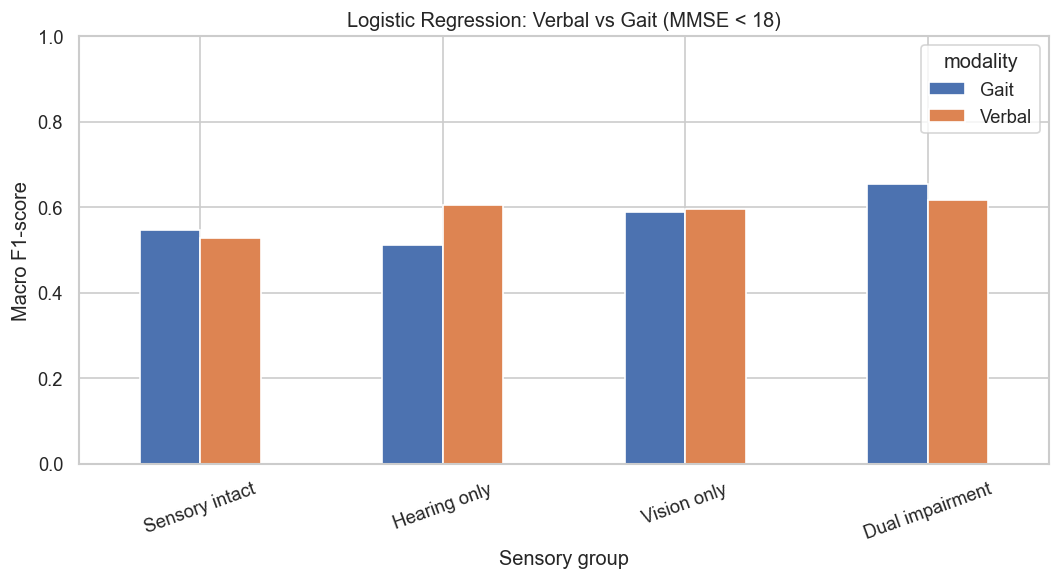

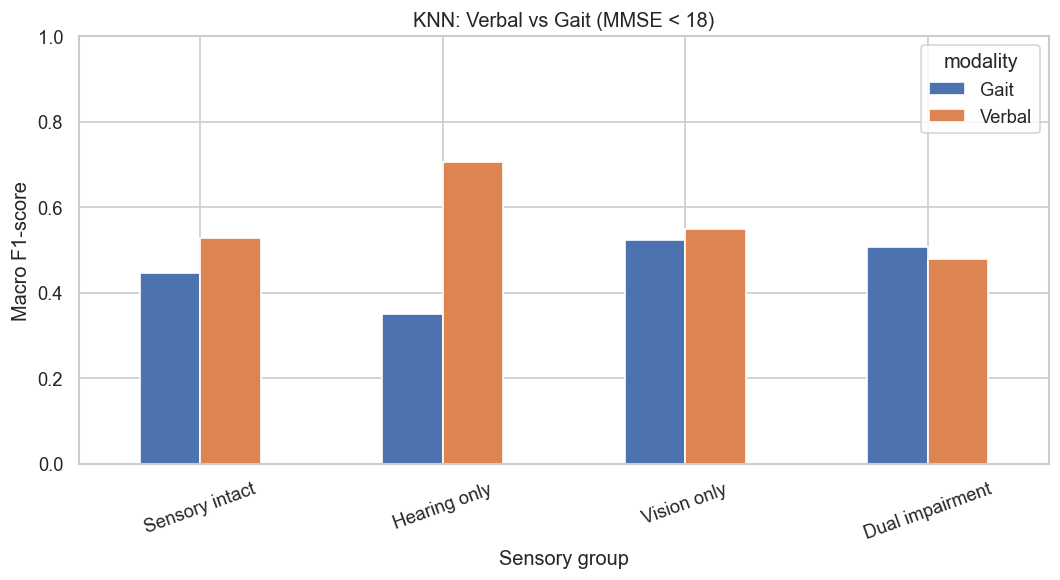

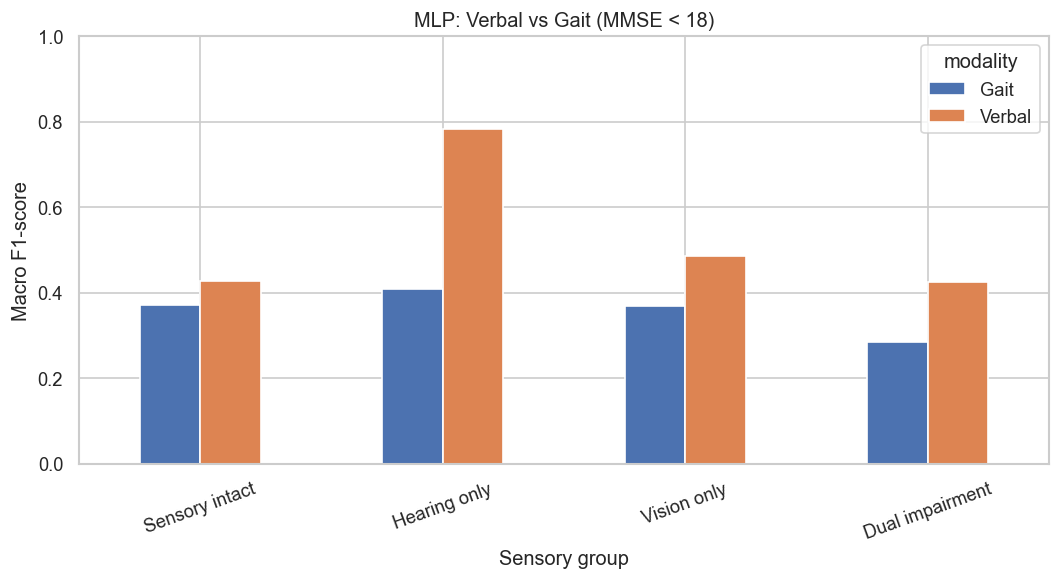

In [30]:
import matplotlib.pyplot as plt

cutoff = 18

plot_df = results_df[
    results_df["mmse_cutoff_exclusive"] == cutoff
]

for model_name in [
    "Logistic Regression",
    "KNN",
    "MLP"
]:

    subset = plot_df[
        plot_df["model"] == model_name
    ]

    pivot = subset.pivot(
        index="group",
        columns="modality",
        values="macro_f1"
    )

    pivot = pivot.reindex(GROUPS)

    ax = pivot.plot(
        kind="bar",
        figsize=(9, 5)
    )

    ax.set_title(
        f"{model_name}: Verbal vs Gait (MMSE < {cutoff})"
    )
    ax.set_xlabel("Sensory group")
    ax.set_ylabel("Macro F1-score")
    ax.set_ylim(0, 1)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

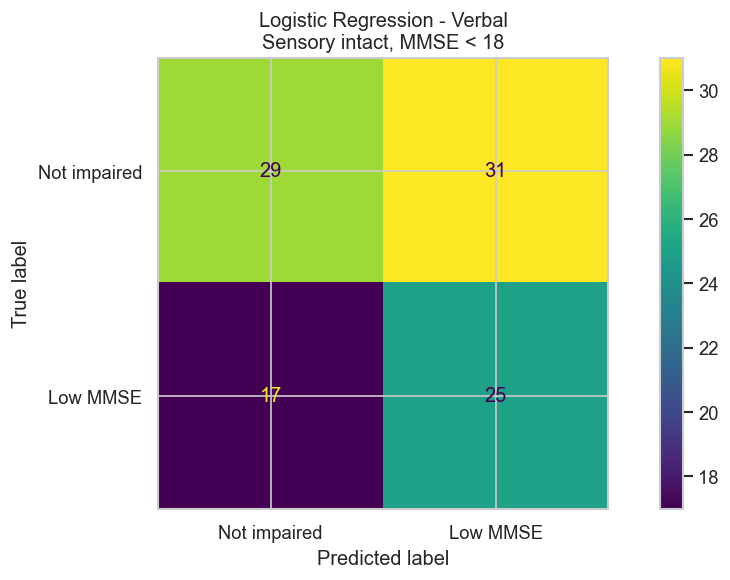

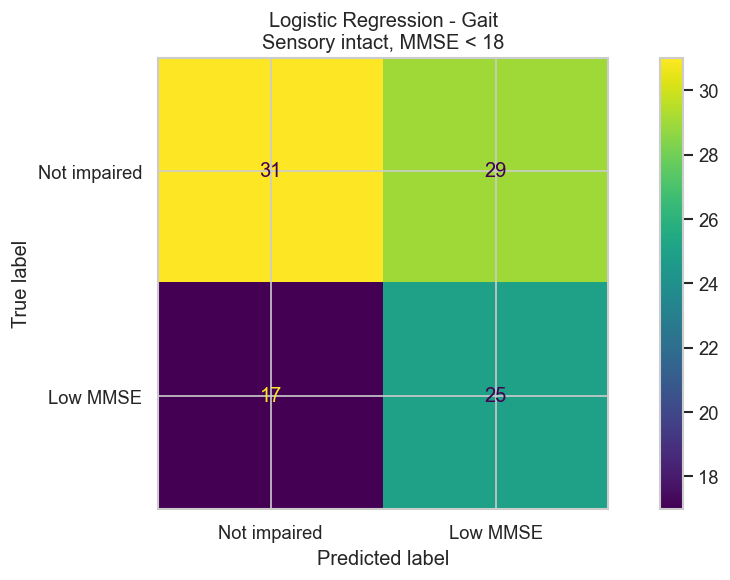

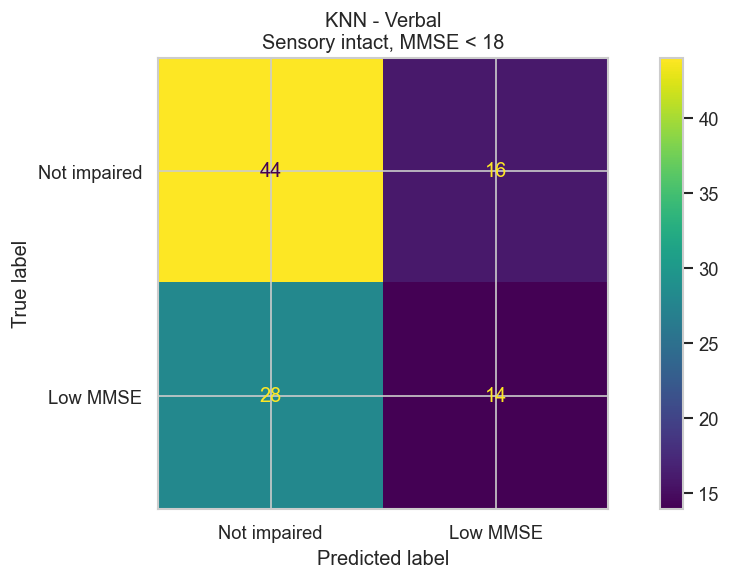

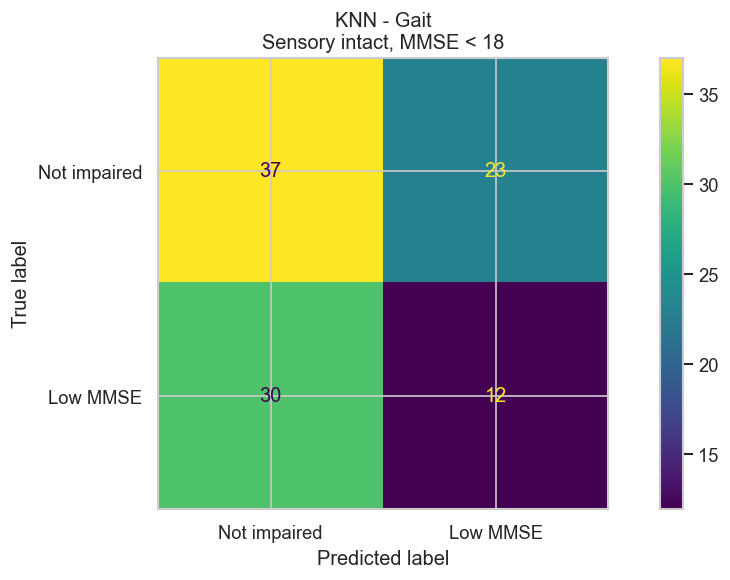

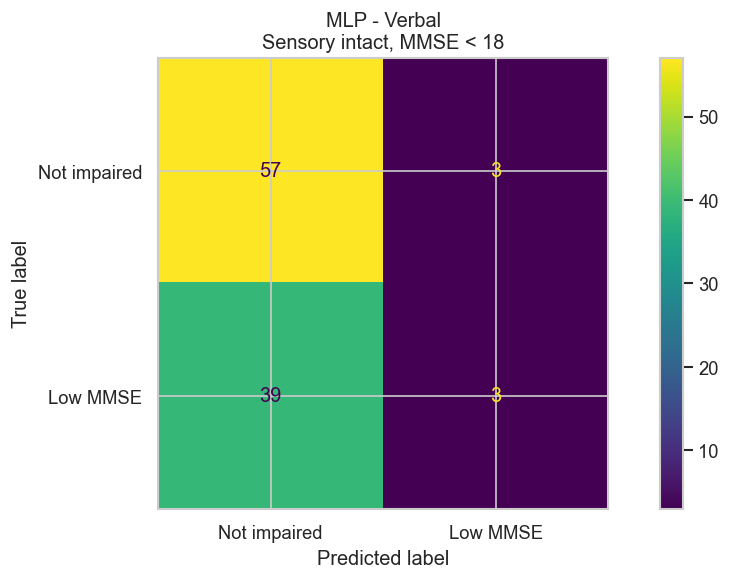

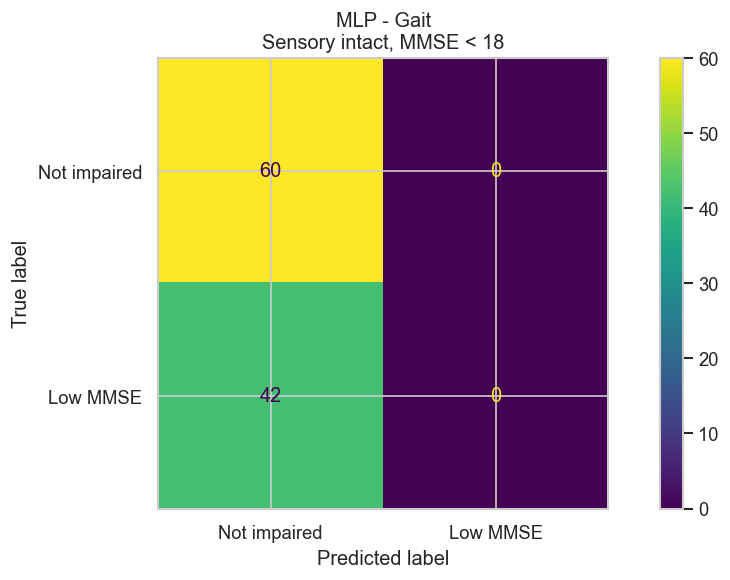

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

cutoff = 18

for model_name in [
    "Logistic Regression",
    "KNN",
    "MLP"
]:

    for modality in ["Verbal", "Gait"]:

        subset = predictions_df[
            (predictions_df["mmse_cutoff_exclusive"] == cutoff)
            & (predictions_df["model"] == model_name)
            & (predictions_df["modality"] == modality)
            & (predictions_df["group"] == "Sensory intact")
        ]

        cm = confusion_matrix(
            subset["y_true"],
            subset["y_pred"],
            labels=[0, 1]
        )

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Not impaired", "Low MMSE"]
        ).plot()

        plt.title(
            f"{model_name} - {modality}\n"
            f"Sensory intact, MMSE < {cutoff}"
        )

        plt.tight_layout()
        plt.show()

## 9. Primary tuned experiment: nested cross-validation

**Main analysis.** The nested procedure uses 5 outer folds, 3 inner folds and `GridSearchCV(scoring="f1_macro")` on the sensory-intact cohort. The pipeline steps are `imputer`, `scaler`, `clf` (not `classifier`). The final search fits on all sensory-intact participants before evaluating frozen models on sensory-impaired cohorts. Target: **MMSE < 18**.

In [32]:
SEED = 42

In [33]:
outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=SEED + 1
)

model_configs = {
    "Logistic Regression": (
        LogisticRegression(
            class_weight="balanced",
            max_iter=1500,
            random_state=SEED
        ),
        {"clf__C": [0.1, 1, 10]}
    ),

    "KNN": (
        KNeighborsClassifier(),
        {
            "clf__n_neighbors": [3, 5, 7, 9],
            "clf__weights": ["uniform", "distance"]
        }
    ),

    "MLP": (
        MLPClassifier(
            max_iter=800,
            early_stopping=False,
            random_state=SEED
        ),
        {
            "clf__hidden_layer_sizes": [(8,), (16,)],
            "clf__alpha": [0.1, 1.0]
        }
    )
}

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

tuned_results = []
tuned_predictions = []
tuned_parameters = []

MMSE_CUTOFF = 18

data = df.copy()

data["y"] = (
    data["w2_mmse_total"] < MMSE_CUTOFF
).astype(int)


intact = data[
    data["sensory_group"] == "Sensory intact"
].copy()

print("Training participants:", len(intact))
print("Class distribution:")
print(intact["y"].value_counts())

for modality, columns in FEATURES.items():

    X_train = intact[columns]
    y_train = intact["y"]

    for model_name, (estimator, param_grid) in model_configs.items():

        print(f"\nTuning {model_name} - {modality}")

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", clone(estimator))
        ])

        # Store predictions from outer CV
        oof_preds = np.zeros(len(intact), dtype=int)

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X_train, y_train),
            start=1
        ):

            X_fold_train = X_train.iloc[train_idx]
            X_fold_test = X_train.iloc[test_idx]

            y_fold_train = y_train.iloc[train_idx]

            search = GridSearchCV(
                estimator=clone(pipeline),
                param_grid=param_grid,
                scoring="f1_macro",
                cv=inner_cv,
                n_jobs=-1
            )

            search.fit(X_fold_train, y_fold_train)

            oof_preds[test_idx] = search.predict(
                X_fold_test
            )

            print(
                f"  Fold {fold}: {search.best_params_}"
            )

        # Sensory-intact out-of-fold performance
        metrics = calculate_metrics(
            y_train.to_numpy(),
            oof_preds
        )

        tuned_results.append({
            "modality": modality,
            "model": model_name,
            "group": "Sensory intact",
            **metrics
        })

        for pid, actual, predicted in zip(
            intact["prim_key"],
            y_train,
            oof_preds
        ):
            tuned_predictions.append({
                "prim_key": pid,
                "modality": modality,
                "model": model_name,
                "group": "Sensory intact",
                "y_true": int(actual),
                "y_pred": int(predicted)
            })

        # Tune final model on all intact participants
        final_search = GridSearchCV(
            estimator=clone(pipeline),
            param_grid=param_grid,
            scoring="f1_macro",
            cv=inner_cv,
            n_jobs=-1
        )

        final_search.fit(X_train, y_train)

        final_model = final_search.best_estimator_

        tuned_parameters.append({
            "modality": modality,
            "model": model_name,
            "best_params": str(final_search.best_params_),
            "best_score": final_search.best_score_
        })

        # Evaluate the frozen model on impaired groups
        for group in GROUPS:

            if group == "Sensory intact":
                continue

            group_data = data[
                data["sensory_group"] == group
            ]

            if group_data.empty:
                continue

            X_group = group_data[columns]
            y_group = group_data["y"]

            preds = final_model.predict(X_group)

            metrics = calculate_metrics(
                y_group.to_numpy(),
                preds
            )

            tuned_results.append({
                "modality": modality,
                "model": model_name,
                "group": group,
                **metrics
            })

            for pid, actual, predicted in zip(
                group_data["prim_key"],
                y_group,
                preds
            ):
                tuned_predictions.append({
                    "prim_key": pid,
                    "modality": modality,
                    "model": model_name,
                    "group": group,
                    "y_true": int(actual),
                    "y_pred": int(predicted)
                })


tuned_results_df = pd.DataFrame(tuned_results)
tuned_predictions_df = pd.DataFrame(tuned_predictions)
tuned_parameters_df = pd.DataFrame(tuned_parameters)

print("\nHyperparameter tuning completed!")

Training participants: 102
Class distribution:
y
0    60
1    42
Name: count, dtype: int64

Tuning Logistic Regression - Verbal
  Fold 1: {'clf__C': 0.1}
  Fold 2: {'clf__C': 0.1}
  Fold 3: {'clf__C': 1}
  Fold 4: {'clf__C': 1}
  Fold 5: {'clf__C': 0.1}

Tuning KNN - Verbal
  Fold 1: {'clf__n_neighbors': 7, 'clf__weights': 'uniform'}
  Fold 2: {'clf__n_neighbors': 5, 'clf__weights': 'uniform'}
  Fold 3: {'clf__n_neighbors': 9, 'clf__weights': 'uniform'}
  Fold 4: {'clf__n_neighbors': 3, 'clf__weights': 'distance'}
  Fold 5: {'clf__n_neighbors': 7, 'clf__weights': 'uniform'}

Tuning MLP - Verbal
  Fold 1: {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (16,)}
  Fold 2: {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (16,)}
  Fold 3: {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (8,)}
  Fold 4: {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (16,)}
  Fold 5: {'clf__alpha': 1.0, 'clf__hidden_layer_sizes': (8,)}

Tuning Logistic Regression - Gait
  Fold 1: {'clf__C': 0.1}
  Fold 2: {'clf__C'

## 10. Primary tuned-model results

`tuned_results_df`, `tuned_predictions_df` and `tuned_parameters_df` are the authoritative results for the primary classifier comparison.

In [35]:
display(
    tuned_results_df[
        [
            "model",
            "modality",
            "group",
            "n",
            "macro_f1",
            "sensitivity",
            "specificity",
            "kappa"
        ]
    ].round(3)
)

print("\nBest hyperparameters:")
display(tuned_parameters_df)

,model,modality,group,n,macro_f1,sensitivity,specificity,kappa
0,Logistic Regression,Verbal,Sensory intact,102,0.519,0.595,0.467,0.059
1,Logistic Regression,Verbal,Hearing only,13,0.606,0.750,0.556,0.253
2,Logistic Regression,Verbal,Vision only,337,0.596,0.543,0.650,0.192
3,Logistic Regression,Verbal,Dual impairment,108,0.618,0.585,0.674,0.246
4,KNN,Verbal,Sensory intact,102,0.531,0.381,0.683,0.066
5,KNN,Verbal,Hearing only,13,0.819,0.750,0.889,0.639
6,KNN,Verbal,Vision only,337,0.531,0.314,0.766,0.085
7,KNN,Verbal,Dual impairment,108,0.479,0.338,0.698,0.032
8,MLP,Verbal,Sensory intact,102,0.528,0.238,0.867,0.115
9,MLP,Verbal,Hearing only,13,0.783,0.500,1.000,0.581



Best hyperparameters:


,modality,model,best_params,best_score
0,Verbal,Logistic Regression,{'clf__C': 0.1},0.487994
1,Verbal,KNN,"{'clf__n_neighbors': 9, 'clf__weights': 'unifo...",0.546673
2,Verbal,MLP,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.579626
3,Gait,Logistic Regression,{'clf__C': 0.1},0.459449
4,Gait,KNN,"{'clf__n_neighbors': 7, 'clf__weights': 'dista...",0.491288
5,Gait,MLP,"{'clf__alpha': 1.0, 'clf__hidden_layer_sizes':...",0.385582


In [36]:
original = results_df[
    results_df["mmse_cutoff_exclusive"] == 18
][
    ["model", "modality", "group", "macro_f1"]
].copy()

original = original.rename(
    columns={"macro_f1": "original_f1"}
)

tuned = tuned_results_df[
    ["model", "modality", "group", "macro_f1"]
].copy()

tuned = tuned.rename(
    columns={"macro_f1": "tuned_f1"}
)

comparison = original.merge(
    tuned,
    on=["model", "modality", "group"]
)

comparison["improvement"] = (
    comparison["tuned_f1"] - comparison["original_f1"]
)

display(comparison.round(3))

,model,modality,group,original_f1,tuned_f1,improvement
0,Logistic Regression,Verbal,Sensory intact,0.529,0.519,-0.009
1,Logistic Regression,Verbal,Hearing only,0.606,0.606,0.000
2,Logistic Regression,Verbal,Vision only,0.596,0.596,0.000
3,Logistic Regression,Verbal,Dual impairment,0.618,0.618,0.000
4,KNN,Verbal,Sensory intact,0.528,0.531,0.003
5,KNN,Verbal,Hearing only,0.707,0.819,0.113
6,KNN,Verbal,Vision only,0.549,0.531,-0.017
7,KNN,Verbal,Dual impairment,0.480,0.479,-0.001
8,MLP,Verbal,Sensory intact,0.428,0.528,0.100
9,MLP,Verbal,Hearing only,0.783,0.783,0.000


## 11. Missing gait data and selection bias

Investigate missing gait times, reasons for non-participation, sensory-group differences, and associations with MMSE. These analyses inform the complete-case limitation.

In [37]:
# Reload the full dataset to investigate missingness
full_df = pd.read_csv(
    "haalsi_w2_modelling_prepared.csv"
)

missingness = full_df.groupby("sensory_group").agg(
    participants=("prim_key", "count"),
    single_task_available=("single_task_speed", "count"),
    dual_task_available=("dual_task_cost_pct", "count"),
    unable_dual_task=("dual_task_unable", "sum"),
    complete_paired=("paired_complete", "sum")
)

missingness["missing_paired_pct"] = (
    100 * (
        1 - missingness["complete_paired"]
        / missingness["participants"]
    )
)

display(missingness.round(2))

,participants,single_task_available,dual_task_available,unable_dual_task,complete_paired,missing_paired_pct
sensory_group,,,,,,
Dual impairment,146,109,108,16,108,26.03
Hearing only,13,13,13,0,13,0.00
Sensory intact,109,103,102,3,102,6.42
Unknown,1,0,0,1,0,100.00
Vision only,392,340,338,15,337,14.03


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the full merged dataset, before complete-case filtering
full_df = pd.read_csv("haalsi_w2_merged_corrected.csv")

print("Full dataset shape:", full_df.shape)
print("\nSensory groups:")
print(full_df["sensory_group"].value_counts(dropna=False))

Full dataset shape: (661, 33)

Sensory groups:
sensory_group
Vision only        392
Dual impairment    146
Sensory intact     109
Hearing only        13
Unknown              1
Name: count, dtype: int64


In [39]:
# Check missing gait measurements

gait_columns = [
    "w2_balance_gait",
    "w2_balance_dualtask_time",
    "w2_balance_dualtask"
]

missing_gait = pd.DataFrame({
    "Missing": full_df[gait_columns].isna().sum(),
    "Available": full_df[gait_columns].notna().sum(),
    "Missing (%)": (
        full_df[gait_columns].isna().mean() * 100
    ).round(2)
})

display(missing_gait)

,Missing,Available,Missing (%)
w2_balance_gait,96,565,14.52
w2_balance_dualtask_time,100,561,15.13
w2_balance_dualtask,30,631,4.54


In [40]:
# Examine missingness patterns

single_missing = full_df["w2_balance_gait"].isna()
dual_missing = full_df["w2_balance_dualtask_time"].isna()

patterns = pd.DataFrame({
    "Both available": [
        (~single_missing & ~dual_missing).sum()
    ],
    "Single missing only": [
        (single_missing & ~dual_missing).sum()
    ],
    "Dual missing only": [
        (~single_missing & dual_missing).sum()
    ],
    "Both missing": [
        (single_missing & dual_missing).sum()
    ]
})

display(patterns.T.rename(columns={0: "Participants"}))

,Participants
Both available,561
Single missing only,0
Dual missing only,4
Both missing,96


In [41]:
# Investigate participants unable to perform the dual-task assessment

full_df["dual_task_unable"] = (
    pd.to_numeric(
        full_df["w2_balance_dualtask"],
        errors="coerce"
    ) == 6
)

print("Unable to participate:")
print(full_df["dual_task_unable"].sum())

unable_summary = pd.crosstab(
    full_df["dual_task_unable"],
    [
        full_df["w2_balance_gait"].isna(),
        full_df["w2_balance_dualtask_time"].isna()
    ],
    rownames=["Unable to participate"],
    colnames=[
        "Single-task missing",
        "Dual-task missing"
    ]
)

display(unable_summary)

Unable to participate:
0


Single-task missing   False       True 
Dual-task missing     False True  True 
Unable to participate                  
False                   561     4    96

In [42]:
# Missing gait measurements by sensory group

full_df["single_missing"] = (
    full_df["w2_balance_gait"].isna()
)

full_df["dual_missing"] = (
    full_df["w2_balance_dualtask_time"].isna()
)

full_df["both_gait_available"] = (
    ~full_df["single_missing"]
    & ~full_df["dual_missing"]
)

full_df["both_gait_missing"] = (
    full_df["single_missing"]
    & full_df["dual_missing"]
)

missing_by_group = full_df.groupby(
    "sensory_group"
).agg(
    participants=("prim_key", "count"),
    single_missing=("single_missing", "sum"),
    dual_missing=("dual_missing", "sum"),
    both_missing=("both_gait_missing", "sum"),
    both_available=("both_gait_available", "sum"),
    unable_dual_task=("dual_task_unable", "sum")
)

for column in [
    "single_missing",
    "dual_missing",
    "both_missing",
    "unable_dual_task"
]:
    missing_by_group[column + "_pct"] = (
        missing_by_group[column]
        / missing_by_group["participants"]
        * 100
    )

display(missing_by_group.round(2))

,participants,single_missing,dual_missing,both_missing,both_available,unable_dual_task,single_missing_pct,dual_missing_pct,both_missing_pct,unable_dual_task_pct
sensory_group,,,,,,,,,,
Dual impairment,146,37,38,37,108,0,25.34,26.03,25.34,0.0
Hearing only,13,0,0,0,13,0,0.00,0.00,0.00,0.0
Sensory intact,109,6,7,6,102,0,5.50,6.42,5.50,0.0
Unknown,1,1,1,1,0,0,100.00,100.00,100.00,0.0
Vision only,392,52,54,52,338,0,13.27,13.78,13.27,0.0


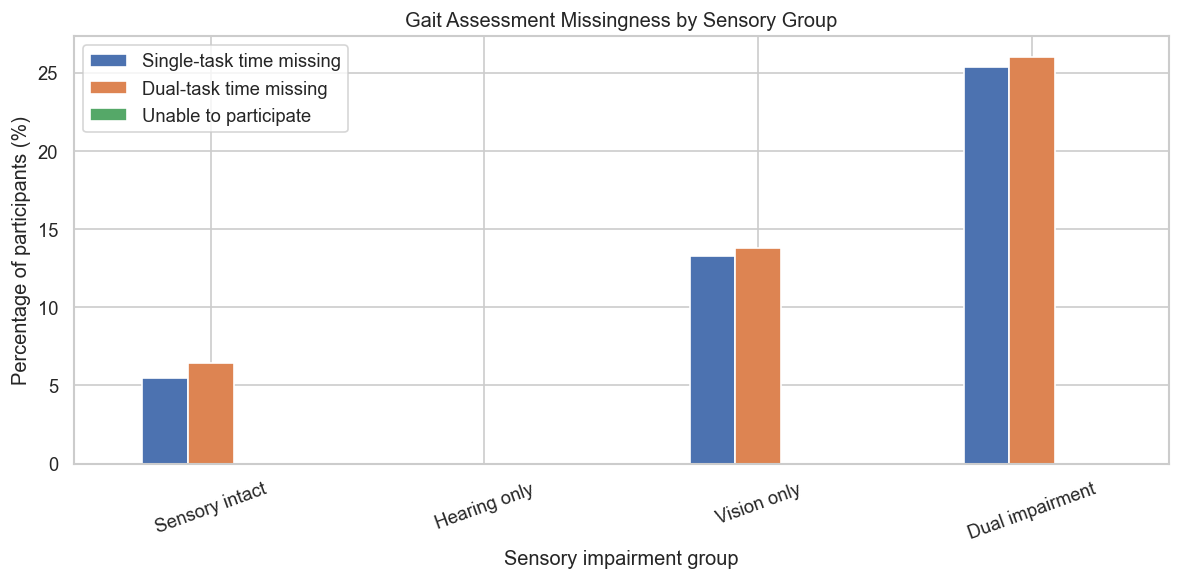

In [43]:
# Visualise missingness by sensory group

groups = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

plot_df = missing_by_group.reindex(groups)

ax = plot_df[
    [
        "single_missing_pct",
        "dual_missing_pct",
        "unable_dual_task_pct"
    ]
].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title(
    "Gait Assessment Missingness by Sensory Group"
)

ax.set_xlabel("Sensory impairment group")
ax.set_ylabel("Percentage of participants (%)")

ax.legend([
    "Single-task time missing",
    "Dual-task time missing",
    "Unable to participate"
])

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [44]:
# Statistical test for missingness

from scipy.stats import chi2_contingency

analysis_groups = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

test_df = full_df[
    full_df["sensory_group"].isin(analysis_groups)
].copy()

contingency = pd.crosstab(
    test_df["sensory_group"],
    test_df["both_gait_available"]
).reindex(analysis_groups)

print("Observed counts:")
display(contingency)

chi2, p_value, dof, expected = chi2_contingency(
    contingency
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6f}")

expected_df = pd.DataFrame(
    expected,
    index=contingency.index,
    columns=contingency.columns
)

print("\nExpected counts:")
display(expected_df.round(2))

print(
    "\nNumber of expected cells below 5:",
    (expected < 5).sum()
)

Observed counts:


both_gait_available,False,True
sensory_group,,
Sensory intact,7,102
Hearing only,0,13
Vision only,54,338
Dual impairment,38,108


Chi-square statistic: 22.9704
Degrees of freedom: 3
p-value: 0.000041

Expected counts:


both_gait_available,False,True
sensory_group,,
Sensory intact,16.35,92.65
Hearing only,1.95,11.05
Vision only,58.80,333.20
Dual impairment,21.90,124.10



Number of expected cells below 5: 1


In [45]:
# Check whether missing gait data is related to MMSE

mmse_missingness_summary = (
    full_df.groupby("both_gait_available")[
        "w2_mmse_total"
    ]
    .agg(["count", "mean", "median", "std"])
)

display(mmse_missingness_summary.round(2))

,count,mean,median,std
both_gait_available,,,,
False,97,14.37,14.0,5.64
True,560,18.35,18.0,5.37


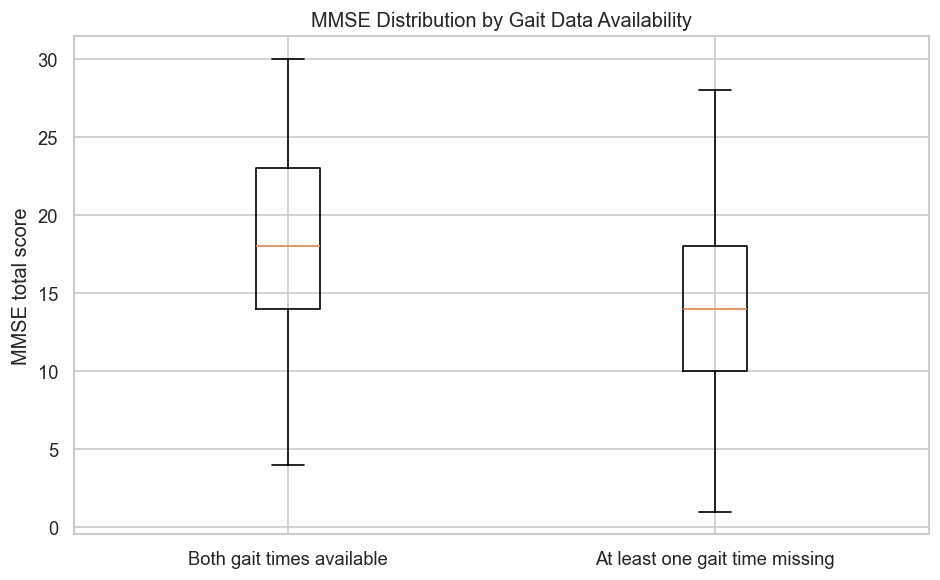

In [46]:
# Visualise

available_mmse = full_df.loc[
    full_df["both_gait_available"],
    "w2_mmse_total"
].dropna()

missing_mmse = full_df.loc[
    ~full_df["both_gait_available"],
    "w2_mmse_total"
].dropna()

plt.figure(figsize=(8, 5))

plt.boxplot(
    [available_mmse, missing_mmse],
    tick_labels=[
        "Both gait times available",
        "At least one gait time missing"
    ]
)

plt.ylabel("MMSE total score")
plt.title("MMSE Distribution by Gait Data Availability")
plt.tight_layout()
plt.show()

In [47]:
print("Original dual-task categories:")

print(
    full_df["w2_balance_dualtask"]
    .value_counts(dropna=False)
)

Original dual-task categories:
w2_balance_dualtask
Success:continued walking during the task                       323
Stop: stopped walking while talking                             177
Mistake:calls out the names of animals that are not 4-legged     59
Unable to participate'                                           35
NaN                                                              30
Stopped and made mistakes                                        28
Continued walking but made mistakes                               9
Name: count, dtype: int64


In [ ]:
# fixing the unable to participate because before it was giving a zero
full_df["dual_task_unable"] = (
    full_df["w2_balance_dualtask"]
    .astype("string")
    .str.contains(
        "Unable to participate",
        case=False,
        na=False,
        regex=False
    )
)

print(
    "Unable to participate:",
    full_df["dual_task_unable"].sum()
)

# Check whether these participants have missing gait times
display(
    pd.crosstab(
        full_df["dual_task_unable"],
        [
            full_df["w2_balance_gait"].isna(),
            full_df["w2_balance_dualtask_time"].isna()
        ],
        margins=True
    )
)

Unable to participate: 35


w2_balance_gait          False      True  All
w2_balance_dualtask_time False True True     
dual_task_unable                             
False                      561    3   62  626
True                         0    1   34   35
All                        561    4   96  661

In [49]:
from scipy.stats import mannwhitneyu

mmse_complete = full_df.loc[
    full_df["both_gait_available"],
    "w2_mmse_total"
].dropna()

mmse_incomplete = full_df.loc[
    ~full_df["both_gait_available"],
    "w2_mmse_total"
].dropna()

statistic, p_value = mannwhitneyu(
    mmse_complete,
    mmse_incomplete,
    alternative="two-sided"
)

print(f"Mann-Whitney U: {statistic:.2f}")
print(f"p-value: {p_value:.6f}")

print(
    "Median MMSE (complete gait):",
    mmse_complete.median()
)

print(
    "Median MMSE (incomplete gait):",
    mmse_incomplete.median()
)

Mann-Whitney U: 37719.50
p-value: 0.000000
Median MMSE (complete gait): 18.0
Median MMSE (incomplete gait): 14.0


In [50]:
# Participants missing both walking times
# without documented inability to participate

investigate = full_df.loc[
    full_df["w2_balance_gait"].isna()
    & full_df["w2_balance_dualtask_time"].isna()
    & ~full_df["dual_task_unable"]
].copy()

print("Participants to investigate:", len(investigate))

print("\nDual-task assessment categories:")
print(
    investigate["w2_balance_dualtask"]
    .value_counts(dropna=False)
)

print("\nSensory groups:")
print(
    investigate["sensory_group"]
    .value_counts(dropna=False)
)

print("\nMMSE availability:")
print(
    investigate["w2_mmse_total"]
    .agg(["count", "mean", "median"])
)

print("\nOther gait-related assessment fields:")
other_gait_cols = [
    "w2_balance_antalgic_gait",
    "w2_obs_bradykinesia"
]

display(
    investigate[other_gait_cols]
    .isna()
    .sum()
    .to_frame("Missing")
)

Participants to investigate: 62

Dual-task assessment categories:
w2_balance_dualtask
Stop: stopped walking while talking                             30
NaN                                                             15
Success:continued walking during the task                        8
Stopped and made mistakes                                        4
Mistake:calls out the names of animals that are not 4-legged     3
Continued walking but made mistakes                              2
Name: count, dtype: int64

Sensory groups:
sensory_group
Vision only        37
Dual impairment    22
Sensory intact      3
Name: count, dtype: int64

MMSE availability:
count     62.000000
mean      15.306452
median    16.000000
Name: w2_mmse_total, dtype: float64

Other gait-related assessment fields:


,Missing
w2_balance_antalgic_gait,0
w2_obs_bradykinesia,0


In [51]:
# Examine if balance_antalgic_gait and obs_bradykinesia are useful

columns_to_check = [
    "w2_balance_antalgic_gait",
    "w2_obs_bradykinesia",
    "w2_balance_gait",
    "w2_balance_dualtask_time"
]

for col in columns_to_check:
    print(f"\n{'=' * 50}")
    print(col)
    print(f"{'=' * 50}")

    print("Data type:", full_df[col].dtype)

    print("\nMost common values:")
    print(
        full_df[col]
        .value_counts(dropna=False)
        .head(15)
    )

    if col in [
        "w2_balance_gait",
        "w2_balance_dualtask_time"
    ]:
        numeric_values = pd.to_numeric(
            full_df[col],
            errors="coerce"
        )

        print("\nNumeric summary:")
        print(numeric_values.describe())

        print(
            "Non-positive times:",
            (numeric_values <= 0).sum()
        )


w2_balance_antalgic_gait
Data type: str

Most common values:
w2_balance_antalgic_gait
No                     604
Yes, both L&R sides     40
Yes,left side only      10
Yes,right side only      7
Name: count, dtype: int64

w2_obs_bradykinesia
Data type: str

Most common values:
w2_obs_bradykinesia
No      582
 Yes     79
Name: count, dtype: int64

w2_balance_gait
Data type: float64

Most common values:
w2_balance_gait
9.0     110
NaN      96
10.0     87
8.0      59
12.0     52
14.0     42
11.0     40
13.0     32
16.0     24
7.0      22
15.0     22
19.0     15
18.0     12
17.0     10
21.0      6
Name: count, dtype: int64

Numeric summary:
count    565.000000
mean      11.952212
std        4.696028
min        4.000000
25%        9.000000
50%       10.000000
75%       14.000000
max       47.000000
Name: w2_balance_gait, dtype: float64
Non-positive times: 0

w2_balance_dualtask_time
Data type: float64

Most common values:
w2_balance_dualtask_time
NaN     100
12.0     69
14.0     50
10.0    

## 12. Gait imputation validation

Evaluate whether KNN imputation improves over median imputation. This is a methodological diagnostic; the primary comparison retains the complete-case sample.

In [ ]:
# Assess the usefulness of physical indicators
import pandas as pd
import numpy as np


impute_check = full_df.copy()

impute_check["antalgic_binary"] = (
    impute_check["w2_balance_antalgic_gait"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.startswith("yes")
    .astype(int)
)

impute_check["bradykinesia_binary"] = (
    impute_check["w2_obs_bradykinesia"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
    .astype(int)
)

# Compare observed gait times by physical indicator
for indicator in [
    "antalgic_binary",
    "bradykinesia_binary"
]:
    print(f"\n{'=' * 50}")
    print(indicator)
    print(f"{'=' * 50}")

    summary = impute_check.groupby(indicator)[
        [
            "w2_balance_gait",
            "w2_balance_dualtask_time"
        ]
    ].agg(["count", "mean", "median", "std"])

    display(summary.round(2))


antalgic_binary


w2_balance_gait                     w2_balance_dualtask_time  \
                          count   mean median   std                    count   
antalgic_binary                                                                
0                           536  11.92   10.0  4.75                      532   
1                            29  12.52   12.0  3.54                       29   

                                     
                  mean median   std  
antalgic_binary                      
0                15.92   14.0  6.70  
1                17.00   14.0  6.96


bradykinesia_binary


w2_balance_gait                      \
                              count   mean median   std   
bradykinesia_binary                                       
0                               519  11.49   10.0  4.38   
1                                46  17.13   16.0  5.06   

                    w2_balance_dualtask_time                      
                                       count   mean median   std  
bradykinesia_binary                                               
0                                        516  15.21   14.0  6.16  
1                                         45  24.73   24.0  6.66

In [54]:
# Prepare the imputation-validation dataset

from sklearn.impute import KNNImputer
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Use only sensory-intact participants with observed gait times
validation_df = impute_check.loc[
    (impute_check["sensory_group"] == "Sensory intact")
    & impute_check["w2_balance_gait"].notna()
    & impute_check["w2_balance_dualtask_time"].notna()
].copy()

auxiliary_cols = [
    "age",
    "antalgic_binary",
    "bradykinesia_binary"
]

gait_time_cols = [
    "w2_balance_gait",
    "w2_balance_dualtask_time"
]

validation_cols = auxiliary_cols + gait_time_cols

validation_df[validation_cols] = validation_df[
    validation_cols
].apply(pd.to_numeric, errors="coerce")

# Keep complete auxiliary predictors for this validation
validation_df = validation_df.dropna(
    subset=validation_cols
).reset_index(drop=True)

print("Validation participants:", len(validation_df))

display(validation_df[validation_cols].head())

Validation participants: 101


,age,antalgic_binary,bradykinesia_binary,w2_balance_gait,w2_balance_dualtask_time
0,48.0,0,0,9.0,12.0
1,76.0,0,0,8.0,12.0
2,76.0,0,1,12.0,17.0
3,59.0,0,0,10.0,11.0
4,56.0,0,0,9.0,11.0


In [55]:
# Simulate missing gait times and measure imputation accuracy
from sklearn.impute import SimpleImputer, KNNImputer

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for k in [3, 5, 7, 9]:

    actual = []
    predicted = []

    for train_idx, test_idx in cv.split(validation_df):

        train = validation_df.iloc[train_idx].copy()
        test = validation_df.iloc[test_idx].copy()

        # Fit auxiliary preprocessing on training participants only
        aux_imputer = SimpleImputer(strategy="median")

        train_aux = aux_imputer.fit_transform(
            train[auxiliary_cols]
        )
        test_aux = aux_imputer.transform(
            test[auxiliary_cols]
        )

        scaler = StandardScaler()

        train_aux = scaler.fit_transform(train_aux)
        test_aux = scaler.transform(test_aux)

        train_matrix = np.column_stack([
            train_aux,
            train[gait_time_cols].to_numpy()
        ])

        # Mask both gait times in the held-out participants
        test_matrix = np.column_stack([
            test_aux,
            np.full((len(test), 2), np.nan)
        ])

        imputer = KNNImputer(
            n_neighbors=k,
            weights="distance"
        )

        imputer.fit(train_matrix)

        reconstructed = imputer.transform(test_matrix)

        predicted.append(reconstructed[:, -2:])
        actual.append(test[gait_time_cols].to_numpy())

    actual = np.vstack(actual)
    predicted = np.vstack(predicted)

    results.append({
        "k": k,
        "single_task_MAE": mean_absolute_error(
            actual[:, 0],
            predicted[:, 0]
        ),
        "dual_task_MAE": mean_absolute_error(
            actual[:, 1],
            predicted[:, 1]
        )
    })

imputation_validation_results = pd.DataFrame(results)

display(imputation_validation_results.round(3))

,k,single_task_MAE,dual_task_MAE
0,3,2.460,3.464
1,5,2.395,3.421
2,7,2.386,3.478
3,9,2.370,3.495


In [56]:
# compare knn against median imputation

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

actual_all = []
median_predictions = []

for train_idx, test_idx in cv.split(validation_df):

    train = validation_df.iloc[train_idx]
    test = validation_df.iloc[test_idx]

    # Calculate medians from training participants only
    train_medians = train[gait_time_cols].median()

    # Predict held-out times using training medians
    predictions = np.tile(
        train_medians.to_numpy(),
        (len(test), 1)
    )

    actual_all.append(
        test[gait_time_cols].to_numpy()
    )

    median_predictions.append(predictions)

actual_all = np.vstack(actual_all)
median_predictions = np.vstack(median_predictions)

median_single_mae = mean_absolute_error(
    actual_all[:, 0],
    median_predictions[:, 0]
)

median_dual_mae = mean_absolute_error(
    actual_all[:, 1],
    median_predictions[:, 1]
)

comparison_df = pd.DataFrame({
    "Method": [
        "Median imputation",
        "KNN (k=5)",
        "KNN (k=7)",
        "KNN (k=9)"
    ],
    "Single-task MAE": [
        median_single_mae,
        *[
            imputation_validation_results.loc[
                imputation_validation_results["k"] == k,
                "single_task_MAE"
            ].iloc[0]
            for k in [5, 7, 9]
        ]
    ],
    "Dual-task MAE": [
        median_dual_mae,
        *[
            imputation_validation_results.loc[
                imputation_validation_results["k"] == k,
                "dual_task_MAE"
            ].iloc[0]
            for k in [5, 7, 9]
        ]
    ]
})

display(comparison_df.round(3))

,Method,Single-task MAE,Dual-task MAE
0,Median imputation,1.703,2.653
1,KNN (k=5),2.395,3.421
2,KNN (k=7),2.386,3.478
3,KNN (k=9),2.370,3.495


## 13. Error analysis: MLP predictions

Inspect class predictions and confusion matrices for tuned MLP models, including low gait-model sensitivity.

In [57]:
# Check whether MLP predicts both classes
mlp_predictions = tuned_predictions_df[
    tuned_predictions_df["model"] == "MLP"
].copy()

summary = (
    mlp_predictions
    .groupby(["modality", "group"])
    .agg(
        participants=("y_true", "size"),
        actual_positive=("y_true", "sum"),
        predicted_positive=("y_pred", "sum")
    )
    .reset_index()
)

summary["predicted_positive_pct"] = (
    summary["predicted_positive"]
    / summary["participants"]
    * 100
)

display(summary.round(2))

,modality,group,participants,actual_positive,predicted_positive,predicted_positive_pct
0,Gait,Dual impairment,108,65,7,6.48
1,Gait,Hearing only,13,4,0,0.00
2,Gait,Sensory intact,102,42,4,3.92
3,Gait,Vision only,337,140,5,1.48
4,Verbal,Dual impairment,108,65,20,18.52
5,Verbal,Hearing only,13,4,2,15.38
6,Verbal,Sensory intact,102,42,18,17.65
7,Verbal,Vision only,337,140,52,15.43


In [58]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd
from pathlib import Path

groups = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

output_file = Path("MLP_Confusion_Matrices_Report.txt")

with open(output_file, "w", encoding="utf-8") as f:

    f.write("MLP CLASSIFICATION DIAGNOSTICS\n")
    f.write("=" * 65 + "\n")
    f.write("MMSE impairment threshold: < 18\n\n")

    for modality in ["Verbal", "Gait"]:

        f.write("\n" + "=" * 65 + "\n")
        f.write(f"MLP MODEL — {modality.upper()}\n")
        f.write("=" * 65 + "\n")

        for group in groups:

            subset = tuned_predictions_df[
                (tuned_predictions_df["model"] == "MLP")
                & (tuned_predictions_df["modality"] == modality)
                & (tuned_predictions_df["group"] == group)
            ]

            if subset.empty:
                f.write(f"\nGroup: {group} — No predictions found\n")
                continue

            y_true = subset["y_true"]
            y_pred = subset["y_pred"]

            cm = confusion_matrix(
                y_true,
                y_pred,
                labels=[0, 1]
            )

            cm_df = pd.DataFrame(
                cm,
                index=["Actual 0", "Actual 1"],
                columns=["Predicted 0", "Predicted 1"]
            )

            report = classification_report(
                y_true,
                y_pred,
                labels=[0, 1],
                zero_division=0
            )

            f.write("\n" + "-" * 65 + "\n")
            f.write(f"GROUP: {group}\n")
            f.write(f"Participants: {len(subset)}\n")
            f.write("-" * 65 + "\n\n")

            f.write("CONFUSION MATRIX\n")
            f.write(cm_df.to_string())
            f.write("\n\n")

            f.write("CLASSIFICATION REPORT\n")
            f.write(report)
            f.write("\n")

            tn, fp, fn, tp = cm.ravel()

            f.write("\nADDITIONAL DIAGNOSTICS\n")
            f.write(f"True negatives: {tn}\n")
            f.write(f"False positives: {fp}\n")
            f.write(f"False negatives: {fn}\n")
            f.write(f"True positives: {tp}\n")

            f.write(
                f"Actual impaired participants: {int(y_true.sum())}\n"
            )

            f.write(
                f"Predicted impaired participants: {int(y_pred.sum())}\n"
            )

            f.write("\n")

print(f"Report saved successfully: {output_file.resolve()}")

Report saved successfully: C:\Users\Wits student\Downloads\Research training\MLP_Confusion_Matrices_Report.txt


## 14. Statistical analysis: paired verbal versus gait comparison

All comparisons in this section use `tuned_predictions_df` from the **primary tuned MMSE < 18 experiment**. Predictions are paired by participant, classifier and sensory group.

In [59]:
import pandas as pd

print("Prediction dataset shape:")
print(tuned_predictions_df.shape)

print("\nAvailable columns:")
print(tuned_predictions_df.columns.tolist())

print("\nModels:")
print(tuned_predictions_df["model"].value_counts())

print("\nModalities:")
print(tuned_predictions_df["modality"].value_counts())

print("\nSensory groups:")
print(tuned_predictions_df["group"].value_counts())

print("\nFirst five rows:")
display(tuned_predictions_df.head())

Prediction dataset shape:
(3360, 6)

Available columns:
['prim_key', 'modality', 'model', 'group', 'y_true', 'y_pred']

Models:
model
Logistic Regression    1120
KNN                    1120
MLP                    1120
Name: count, dtype: int64

Modalities:
modality
Verbal    1680
Gait      1680
Name: count, dtype: int64

Sensory groups:
group
Vision only        2022
Dual impairment     648
Sensory intact      612
Hearing only         78
Name: count, dtype: int64

First five rows:


,prim_key,modality,model,group,y_true,y_pred
0,BGXOZ,Verbal,Logistic Regression,Sensory intact,0,0
1,BJXWB,Verbal,Logistic Regression,Sensory intact,1,0
2,BMRBL,Verbal,Logistic Regression,Sensory intact,0,1
3,BSTZG,Verbal,Logistic Regression,Sensory intact,0,0
4,BVRGE,Verbal,Logistic Regression,Sensory intact,0,0


In [60]:


# -------------------------------------------
# 1. Check for duplicate prediction records
# -------------------------------------------

keys = ["prim_key", "model", "group", "modality"]

duplicates = tuned_predictions_df.duplicated(
    subset=keys
).sum()

print("Duplicate prediction records:", duplicates)

assert duplicates == 0, "Duplicate prediction records found!"


# -------------------------------------------
# 2. Separate verbal and gait predictions
# -------------------------------------------

verbal_df = tuned_predictions_df[
    tuned_predictions_df["modality"] == "Verbal"
][
    ["prim_key", "model", "group", "y_true", "y_pred"]
].rename(
    columns={
        "y_true": "y_true_verbal",
        "y_pred": "y_pred_verbal"
    }
)

gait_df = tuned_predictions_df[
    tuned_predictions_df["modality"] == "Gait"
][
    ["prim_key", "model", "group", "y_true", "y_pred"]
].rename(
    columns={
        "y_true": "y_true_gait",
        "y_pred": "y_pred_gait"
    }
)


# -------------------------------------------
# 3. Match predictions by participant
# -------------------------------------------

paired_predictions_df = verbal_df.merge(
    gait_df,
    on=["prim_key", "model", "group"],
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("\nPairing status:")
print(paired_predictions_df["_merge"].value_counts())

assert (
    paired_predictions_df["_merge"] == "both"
).all(), "Some participants do not have paired predictions!"

paired_predictions_df = paired_predictions_df.drop(
    columns="_merge"
)


# -------------------------------------------
# 4. Verify true labels match
# -------------------------------------------

label_mismatches = (
    paired_predictions_df["y_true_verbal"]
    != paired_predictions_df["y_true_gait"]
).sum()

print("\nTrue-label mismatches:", label_mismatches)

assert label_mismatches == 0, "True labels do not match!"


# -------------------------------------------
# 5. Create one shared true-label column
# -------------------------------------------

paired_predictions_df["y_true"] = (
    paired_predictions_df["y_true_verbal"]
)

paired_predictions_df = paired_predictions_df.drop(
    columns=["y_true_verbal", "y_true_gait"]
)


# -------------------------------------------
# 6. Summarise paired participants
# -------------------------------------------

pairing_summary = (
    paired_predictions_df
    .groupby(["model", "group"])
    .agg(
        participants=("prim_key", "nunique"),
        records=("prim_key", "size")
    )
    .reset_index()
)

print("\nPaired prediction summary:")
display(pairing_summary)

print("\nFinal paired dataset shape:")
print(paired_predictions_df.shape)

print("\nFirst five rows:")
display(paired_predictions_df.head())

Duplicate prediction records: 0

Pairing status:
_merge
both          1680
left_only        0
right_only       0
Name: count, dtype: int64

True-label mismatches: 0

Paired prediction summary:


,model,group,participants,records
0,KNN,Dual impairment,108,108
1,KNN,Hearing only,13,13
2,KNN,Sensory intact,102,102
3,KNN,Vision only,337,337
4,Logistic Regression,Dual impairment,108,108
5,Logistic Regression,Hearing only,13,13
6,Logistic Regression,Sensory intact,102,102
7,Logistic Regression,Vision only,337,337
8,MLP,Dual impairment,108,108
9,MLP,Hearing only,13,13



Final paired dataset shape:
(1680, 6)

First five rows:


,prim_key,model,group,y_pred_verbal,y_pred_gait,y_true
0,BBPGJ,KNN,Vision only,0,0,1
1,BBPGJ,Logistic Regression,Vision only,1,0,1
2,BBPGJ,MLP,Vision only,0,0,1
3,BBSPW,KNN,Vision only,0,1,0
4,BBSPW,Logistic Regression,Vision only,0,1,0


## 15. Within-group performance differences

Calculate gait-minus-verbal macro F1 and balanced accuracy and obtain paired, class-stratified bootstrap confidence intervals.

In [61]:
# Verbal versus gait performance
from sklearn.metrics import f1_score, balanced_accuracy_score
import pandas as pd

comparison_results = []

for (model, group), subset in paired_predictions_df.groupby(
    ["model", "group"]
):

    y_true = subset["y_true"]

    verbal_pred = subset["y_pred_verbal"]
    gait_pred = subset["y_pred_gait"]

    verbal_f1 = f1_score(
        y_true,
        verbal_pred,
        average="macro",
        labels=[0, 1],
        zero_division=0
    )

    gait_f1 = f1_score(
        y_true,
        gait_pred,
        average="macro",
        labels=[0, 1],
        zero_division=0
    )

    verbal_ba = balanced_accuracy_score(
        y_true,
        verbal_pred
    )

    gait_ba = balanced_accuracy_score(
        y_true,
        gait_pred
    )

    comparison_results.append({
        "Model": model,
        "Group": group,
        "N": len(subset),

        "Verbal Macro F1": verbal_f1,
        "Gait Macro F1": gait_f1,
        "Delta Macro F1": gait_f1 - verbal_f1,

        "Verbal BA": verbal_ba,
        "Gait BA": gait_ba,
        "Delta BA": gait_ba - verbal_ba
    })

performance_comparison_df = pd.DataFrame(comparison_results)

group_order = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

performance_comparison_df["Group"] = pd.Categorical(
    performance_comparison_df["Group"],
    categories=group_order,
    ordered=True
)

performance_comparison_df = (
    performance_comparison_df
    .sort_values(["Model", "Group"])
    .reset_index(drop=True)
)

display(performance_comparison_df.round(3))

,Model,Group,N,Verbal Macro F1,Gait Macro F1,Delta Macro F1,Verbal BA,Gait BA,Delta BA
0,KNN,Sensory intact,102,0.531,0.377,-0.153,0.532,0.382,-0.150
1,KNN,Hearing only,13,0.819,0.350,-0.469,0.819,0.389,-0.431
2,KNN,Vision only,337,0.531,0.524,-0.007,0.540,0.525,-0.015
3,KNN,Dual impairment,108,0.479,0.507,0.029,0.518,0.545,0.027
4,Logistic Regression,Sensory intact,102,0.519,0.538,0.019,0.531,0.548,0.017
5,Logistic Regression,Hearing only,13,0.606,0.511,-0.095,0.653,0.514,-0.139
6,Logistic Regression,Vision only,337,0.596,0.590,-0.006,0.596,0.600,0.004
7,Logistic Regression,Dual impairment,108,0.618,0.655,0.037,0.630,0.656,0.027
8,MLP,Sensory intact,102,0.528,0.382,-0.145,0.552,0.487,-0.065
9,MLP,Hearing only,13,0.783,0.409,-0.374,0.750,0.500,-0.250


In [62]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score
)

SEED = 42
N_BOOTSTRAPS = 2000

rng = np.random.default_rng(SEED)

bootstrap_results = []

def calculate_metric_differences(y_true, verbal_pred, gait_pred):

    verbal_f1 = f1_score(
        y_true,
        verbal_pred,
        average="macro",
        labels=[0, 1],
        zero_division=0
    )

    gait_f1 = f1_score(
        y_true,
        gait_pred,
        average="macro",
        labels=[0, 1],
        zero_division=0
    )

    verbal_ba = balanced_accuracy_score(y_true, verbal_pred)
    gait_ba = balanced_accuracy_score(y_true, gait_pred)

    return gait_f1 - verbal_f1, gait_ba - verbal_ba


for (model, group), subset in paired_predictions_df.groupby(
    ["model", "group"],
    observed=True
):

    subset = subset.reset_index(drop=True)

    y_true = subset["y_true"].to_numpy()
    verbal_pred = subset["y_pred_verbal"].to_numpy()
    gait_pred = subset["y_pred_gait"].to_numpy()

    # Observed performance differences
    observed_f1, observed_ba = calculate_metric_differences(
        y_true, verbal_pred, gait_pred
    )

    # Preserve observed class counts in every bootstrap sample
    class_indices = {
        cls: np.flatnonzero(y_true == cls)
        for cls in np.unique(y_true)
    }

    boot_f1 = []
    boot_ba = []

    for _ in range(N_BOOTSTRAPS):

        sampled_indices = np.concatenate([
            rng.choice(
                indices,
                size=len(indices),
                replace=True
            )
            for indices in class_indices.values()
        ])

        sampled_true = y_true[sampled_indices]
        sampled_verbal = verbal_pred[sampled_indices]
        sampled_gait = gait_pred[sampled_indices]

        delta_f1, delta_ba = calculate_metric_differences(
            sampled_true,
            sampled_verbal,
            sampled_gait
        )

        boot_f1.append(delta_f1)
        boot_ba.append(delta_ba)

    f1_lower, f1_upper = np.percentile(
        boot_f1, [2.5, 97.5]
    )

    ba_lower, ba_upper = np.percentile(
        boot_ba, [2.5, 97.5]
    )

    bootstrap_results.append({
        "Model": model,
        "Group": group,
        "N": len(subset),

        "Delta Macro F1": observed_f1,
        "F1 CI Lower": f1_lower,
        "F1 CI Upper": f1_upper,

        "Delta BA": observed_ba,
        "BA CI Lower": ba_lower,
        "BA CI Upper": ba_upper
    })


bootstrap_results_df = pd.DataFrame(bootstrap_results)

group_order = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

bootstrap_results_df["Group"] = pd.Categorical(
    bootstrap_results_df["Group"],
    categories=group_order,
    ordered=True
)

bootstrap_results_df = (
    bootstrap_results_df
    .sort_values(["Model", "Group"])
    .reset_index(drop=True)
)

display(bootstrap_results_df.round(3))

,Model,Group,N,Delta Macro F1,F1 CI Lower,F1 CI Upper,Delta BA,BA CI Lower,BA CI Upper
0,KNN,Sensory intact,102,-0.153,-0.270,-0.033,-0.150,-0.264,-0.030
1,KNN,Hearing only,13,-0.469,-0.684,-0.186,-0.431,-0.667,-0.139
2,KNN,Vision only,337,-0.007,-0.085,0.071,-0.015,-0.088,0.059
3,KNN,Dual impairment,108,0.029,-0.098,0.151,0.027,-0.104,0.151
4,Logistic Regression,Sensory intact,102,0.019,-0.119,0.158,0.017,-0.127,0.160
5,Logistic Regression,Hearing only,13,-0.095,-0.395,0.179,-0.139,-0.444,0.153
6,Logistic Regression,Vision only,337,-0.006,-0.082,0.064,0.004,-0.072,0.075
7,Logistic Regression,Dual impairment,108,0.037,-0.094,0.164,0.027,-0.105,0.154
8,MLP,Sensory intact,102,-0.145,-0.248,-0.053,-0.065,-0.150,0.012
9,MLP,Hearing only,13,-0.374,-0.591,0.000,-0.250,-0.500,0.000


## 16. Cross-group robustness analysis

Compare each impaired cohort with the sensory-intact baseline, then bootstrap the difference of gait-minus-verbal gaps.

In [63]:
# Calculate robustness changes
import pandas as pd

robustness_results = []

metrics = [
    ("Macro F1", "Verbal Macro F1", "Gait Macro F1"),
    ("Balanced Accuracy", "Verbal BA", "Gait BA")
]

for model in performance_comparison_df["Model"].unique():

    model_df = performance_comparison_df[
        performance_comparison_df["Model"] == model
    ]

    baseline = model_df[
        model_df["Group"] == "Sensory intact"
    ].iloc[0]

    impaired_groups = model_df[
        model_df["Group"] != "Sensory intact"
    ]

    for _, row in impaired_groups.iterrows():

        for metric_name, verbal_col, gait_col in metrics:

            verbal_change = (
                row[verbal_col] - baseline[verbal_col]
            )

            gait_change = (
                row[gait_col] - baseline[gait_col]
            )

            robustness_difference = (
                gait_change - verbal_change
            )

            robustness_results.append({
                "Model": model,
                "Group": row["Group"],
                "Metric": metric_name,
                "N": row["N"],
                "Verbal Change": verbal_change,
                "Gait Change": gait_change,
                "Robustness Difference": robustness_difference
            })

robustness_df = pd.DataFrame(robustness_results)

group_order = [
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

robustness_df["Group"] = pd.Categorical(
    robustness_df["Group"],
    categories=group_order,
    ordered=True
)

robustness_df = (
    robustness_df
    .sort_values(["Model", "Metric", "Group"])
    .reset_index(drop=True)
)

display(robustness_df.round(3))

,Model,Group,Metric,N,Verbal Change,Gait Change,Robustness Difference
0,KNN,Hearing only,Balanced Accuracy,13,0.287,0.007,-0.281
1,KNN,Vision only,Balanced Accuracy,337,0.008,0.143,0.135
2,KNN,Dual impairment,Balanced Accuracy,108,-0.014,0.163,0.177
3,KNN,Hearing only,Macro F1,13,0.289,-0.027,-0.316
4,KNN,Vision only,Macro F1,337,0.001,0.147,0.146
5,KNN,Dual impairment,Macro F1,108,-0.052,0.130,0.182
6,Logistic Regression,Hearing only,Balanced Accuracy,13,0.122,-0.034,-0.156
7,Logistic Regression,Vision only,Balanced Accuracy,337,0.065,0.053,-0.013
8,Logistic Regression,Dual impairment,Balanced Accuracy,108,0.099,0.109,0.010
9,Logistic Regression,Hearing only,Macro F1,13,0.087,-0.027,-0.114


In [64]:
# Bootstrap robustness differences

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, balanced_accuracy_score

SEED = 42
N_BOOTSTRAPS = 2000

rng = np.random.default_rng(SEED)

def get_modality_gap(data, metric):

    y = data["y_true"].to_numpy()
    verbal = data["y_pred_verbal"].to_numpy()
    gait = data["y_pred_gait"].to_numpy()

    if metric == "Macro F1":
        verbal_score = f1_score(
            y, verbal, average="macro",
            labels=[0, 1], zero_division=0
        )
        gait_score = f1_score(
            y, gait, average="macro",
            labels=[0, 1], zero_division=0
        )

    elif metric == "Balanced Accuracy":
        verbal_score = balanced_accuracy_score(y, verbal)
        gait_score = balanced_accuracy_score(y, gait)

    else:
        raise ValueError("Unknown metric")

    return gait_score - verbal_score


def stratified_resample(data, rng):

    sampled_parts = []

    for _, class_data in data.groupby("y_true"):

        sampled_indices = rng.choice(
            class_data.index.to_numpy(),
            size=len(class_data),
            replace=True
        )

        sampled_parts.append(data.loc[sampled_indices])

    return pd.concat(
        sampled_parts,
        ignore_index=True
    )


robustness_bootstrap_results = []

for model in [
    "Logistic Regression",
    "KNN",
    "MLP"
]:

    model_data = paired_predictions_df[
        paired_predictions_df["model"] == model
    ]

    baseline = model_data[
        model_data["group"] == "Sensory intact"
    ].reset_index(drop=True)

    for group in [
        "Hearing only",
        "Vision only",
        "Dual impairment"
    ]:

        impaired = model_data[
            model_data["group"] == group
        ].reset_index(drop=True)

        for metric in [
            "Macro F1",
            "Balanced Accuracy"
        ]:

            observed = (
                get_modality_gap(impaired, metric)
                - get_modality_gap(baseline, metric)
            )

            bootstrap_values = []

            for _ in range(N_BOOTSTRAPS):

                baseline_sample = stratified_resample(
                    baseline, rng
                )

                impaired_sample = stratified_resample(
                    impaired, rng
                )

                bootstrap_difference = (
                    get_modality_gap(impaired_sample, metric)
                    - get_modality_gap(baseline_sample, metric)
                )

                bootstrap_values.append(
                    bootstrap_difference
                )

            lower, upper = np.percentile(
                bootstrap_values, [2.5, 97.5]
            )

            robustness_bootstrap_results.append({
                "Model": model,
                "Group": group,
                "Metric": metric,
                "N": len(impaired),
                "Robustness Difference": observed,
                "CI Lower": lower,
                "CI Upper": upper
            })


robustness_bootstrap_df = pd.DataFrame(
    robustness_bootstrap_results
)

display(
    robustness_bootstrap_df.round(3)
)

,Model,Group,Metric,N,Robustness Difference,CI Lower,CI Upper
0,Logistic Regression,Hearing only,Macro F1,13,-0.114,-0.460,0.210
1,Logistic Regression,Hearing only,Balanced Accuracy,13,-0.156,-0.472,0.170
2,Logistic Regression,Vision only,Macro F1,337,-0.025,-0.184,0.140
3,Logistic Regression,Vision only,Balanced Accuracy,337,-0.013,-0.167,0.153
4,Logistic Regression,Dual impairment,Macro F1,108,0.018,-0.173,0.211
5,Logistic Regression,Dual impairment,Balanced Accuracy,108,0.010,-0.189,0.192
6,KNN,Hearing only,Macro F1,13,-0.316,-0.578,-0.024
7,KNN,Hearing only,Balanced Accuracy,13,-0.281,-0.585,0.046
8,KNN,Vision only,Macro F1,337,0.146,0.002,0.292
9,KNN,Vision only,Balanced Accuracy,337,0.135,0.002,0.276


## 17. MMSE threshold distribution checks

Check class counts for alternative MMSE thresholds before interpreting sensitivity results. `results_df` already contains an exploratory fixed-parameter threshold analysis; the tuned primary models were only fitted for MMSE < 18.

In [65]:
# Check MMSE distributions for alternative thresholds

import pandas as pd

thresholds = [18, 20, 23, 24]

# Use the same 560 participants as the paired comparison
analysis_ids = paired_predictions_df["prim_key"].unique()

mmse_check = full_df[
    full_df["prim_key"].isin(analysis_ids)
].copy()

mmse_check = mmse_check.dropna(
    subset=["w2_mmse_total"]
)

# Attach the verified sensory-group labels
group_lookup = (
    paired_predictions_df[["prim_key", "group"]]
    .drop_duplicates()
)

mmse_check = mmse_check.drop(
    columns=["group"],
    errors="ignore"
).merge(
    group_lookup,
    on="prim_key",
    how="inner",
    validate="one_to_one"
)

assert mmse_check["prim_key"].nunique() == 560

threshold_results = []

for threshold in thresholds:

    mmse_check["impaired"] = (
        mmse_check["w2_mmse_total"] < threshold
    ).astype(int)

    for group, subset in mmse_check.groupby("group"):

        threshold_results.append({
            "Threshold": f"MMSE < {threshold}",
            "Group": group,
            "N": len(subset),
            "Impaired": subset["impaired"].sum(),
            "Unimpaired": (subset["impaired"] == 0).sum(),
            "Impaired %": subset["impaired"].mean() * 100
        })

threshold_summary_df = pd.DataFrame(threshold_results)

display(
    threshold_summary_df.round(2)
)

,Threshold,Group,N,Impaired,Unimpaired,Impaired %
0,MMSE < 18,Dual impairment,108,65,43,60.19
1,MMSE < 18,Hearing only,13,4,9,30.77
2,MMSE < 18,Sensory intact,102,42,60,41.18
3,MMSE < 18,Vision only,337,140,197,41.54
4,MMSE < 20,Dual impairment,108,82,26,75.93
5,MMSE < 20,Hearing only,13,6,7,46.15
6,MMSE < 20,Sensory intact,102,58,44,56.86
7,MMSE < 20,Vision only,337,192,145,56.97
8,MMSE < 23,Dual impairment,108,90,18,83.33
9,MMSE < 23,Hearing only,13,8,5,61.54


## 18. Notebook inspection and reproducibility checks

Inspect variables and modelling configurations.

In [66]:
# Inspect existing modelling objects without retraining

candidate_names = [
    "best_params",
    "best_params_df",
    "tuned_models",
    "tuned_pipelines",
    "best_models",
    "verbal_features",
    "gait_features",
    "X_verbal",
    "X_gait",
    "df",
    "full_df"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, dict):
            print(f"{name}: dict, keys = {list(obj.keys())[:15]}")
        elif hasattr(obj, "shape"):
            print(f"{name}: {type(obj).__name__}, shape = {obj.shape}")
        else:
            print(f"{name}: {type(obj).__name__}")
    else:
        print(f"{name}: NOT FOUND")
        

best_params: NOT FOUND
best_params_df: NOT FOUND
tuned_models: NOT FOUND
tuned_pipelines: NOT FOUND
best_models: NOT FOUND
verbal_features: NOT FOUND
gait_features: NOT FOUND
X_verbal: NOT FOUND
X_gait: NOT FOUND
df: DataFrame, shape = (560, 24)
full_df: DataFrame, shape = (661, 38)


In [67]:
import inspect

print("=" * 60)
print("1. ORIGINAL FEATURE SETS")
print("=" * 60)

for modality, features in FEATURES.items():
    print(f"\n{modality}:")
    print(features)


print("\n" + "=" * 60)
print("2. TUNED HYPERPARAMETERS")
print("=" * 60)

display(tuned_parameters_df)


print("\n" + "=" * 60)
print("3. MODEL CONFIGURATIONS")
print("=" * 60)

for model_name, config in model_configs.items():
    print(f"\n{model_name}:")
    print(config)


print("\n" + "=" * 60)
print("4. MODEL CONSTRUCTION FUNCTION")
print("=" * 60)

try:
    print(inspect.getsource(make_model))
except (OSError, TypeError):
    print("Source unavailable.")
    print("Function signature:", inspect.signature(make_model))


print("\n" + "=" * 60)
print("5. CROSS-VALIDATION CONFIGURATIONS")
print("=" * 60)

print("Outer CV:", outer_cv)
print("Inner CV:", inner_cv)


print("\n" + "=" * 60)
print("6. MODELLING DATASET COLUMNS")
print("=" * 60)

print(df.columns.tolist())

1. ORIGINAL FEATURE SETS

Verbal:
['Semantic_fluency', 'Logical_Memory_immediate']

Gait:
['single_task_speed', 'dual_task_cost_pct']

2. TUNED HYPERPARAMETERS


,modality,model,best_params,best_score
0,Verbal,Logistic Regression,{'clf__C': 0.1},0.487994
1,Verbal,KNN,"{'clf__n_neighbors': 9, 'clf__weights': 'unifo...",0.546673
2,Verbal,MLP,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.579626
3,Gait,Logistic Regression,{'clf__C': 0.1},0.459449
4,Gait,KNN,"{'clf__n_neighbors': 7, 'clf__weights': 'dista...",0.491288
5,Gait,MLP,"{'clf__alpha': 1.0, 'clf__hidden_layer_sizes':...",0.385582



3. MODEL CONFIGURATIONS

Logistic Regression:
(LogisticRegression(class_weight='balanced', max_iter=1500, random_state=42), {'clf__C': [0.1, 1, 10]})

KNN:
(KNeighborsClassifier(), {'clf__n_neighbors': [3, 5, 7, 9], 'clf__weights': ['uniform', 'distance']})

MLP:
(MLPClassifier(max_iter=800, random_state=42), {'clf__hidden_layer_sizes': [(8,), (16,)], 'clf__alpha': [0.1, 1.0]})

4. MODEL CONSTRUCTION FUNCTION
def make_model(name):

    if name == "Logistic Regression":
        estimator = LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED
        )

    elif name == "KNN":
        estimator = KNeighborsClassifier(
            n_neighbors=7,
            weights="distance"
        )

    elif name == "MLP":
        estimator = MLPClassifier(
            hidden_layer_sizes=(8,),
            alpha=1.0,
            early_stopping=False,
            max_iter=2000,
            random_state=SEED
        )

    else:
        raise 

## Sensitivity analysis and further gait vs verbal analysis

In [ ]:


# Compare verbal and gait macro F1 at each MMSE threshold
threshold_comparison_df = (
    results_df.pivot_table(
        index=[
            "mmse_cutoff_exclusive",
            "model",
            "group"
        ],
        columns="modality",
        values="macro_f1",
        aggfunc="first",
        observed=True
    )
    .reset_index()
)

threshold_comparison_df.columns.name = None

threshold_comparison_df = threshold_comparison_df.rename(
    columns={
        "mmse_cutoff_exclusive": "MMSE Threshold",
        "model": "Model",
        "group": "Group",
        "Verbal": "Verbal Macro F1",
        "Gait": "Gait Macro F1"
    }
)

# Positive difference favours gait
threshold_comparison_df["Gait - Verbal"] = (
    threshold_comparison_df["Gait Macro F1"]
    - threshold_comparison_df["Verbal Macro F1"]
)

group_order = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

threshold_comparison_df["Group"] = pd.Categorical(
    threshold_comparison_df["Group"],
    categories=group_order,
    ordered=True
)

threshold_comparison_df = (
    threshold_comparison_df
    .sort_values(["Model", "MMSE Threshold", "Group"])
    .reset_index(drop=True)
)

print("THRESHOLD SENSITIVITY COMPARISON")
print("Positive difference = gait performs better")
print("Negative difference = verbal performs better")

display(threshold_comparison_df.round(3))

THRESHOLD SENSITIVITY COMPARISON
Positive difference = gait performs better
Negative difference = verbal performs better


,MMSE Threshold,Model,Group,Gait Macro F1,Verbal Macro F1,Gait - Verbal
0,18,KNN,Sensory intact,0.447,0.528,-0.081
1,18,KNN,Hearing only,0.350,0.707,-0.357
2,18,KNN,Vision only,0.524,0.549,-0.024
3,18,KNN,Dual impairment,0.507,0.480,0.027
4,20,KNN,Sensory intact,0.514,0.604,-0.090
5,20,KNN,Hearing only,0.512,0.606,-0.094
6,20,KNN,Vision only,0.511,0.561,-0.050
7,20,KNN,Dual impairment,0.537,0.498,0.039
8,23,KNN,Sensory intact,0.465,0.559,-0.094
9,23,KNN,Hearing only,0.458,0.606,-0.148


In [69]:
# Threshold consistency summary

threshold_consistency_df = (
    threshold_comparison_df
    .groupby(["Model", "Group"], observed=True)
    .agg(
        Thresholds_Tested=("MMSE Threshold", "nunique"),
        Gait_Better=("Gait - Verbal", lambda x: (x > 0).sum()),
        Verbal_Better=("Gait - Verbal", lambda x: (x < 0).sum()),
        Equal=("Gait - Verbal", lambda x: (x == 0).sum()),
        Mean_Difference=("Gait - Verbal", "mean"),
        Min_Difference=("Gait - Verbal", "min"),
        Max_Difference=("Gait - Verbal", "max")
    )
    .reset_index()
)

display(threshold_consistency_df.round(3))

,Model,Group,Thresholds_Tested,Gait_Better,Verbal_Better,Equal,Mean_Difference,Min_Difference,Max_Difference
0,KNN,Sensory intact,4,0,4,0,-0.088,-0.094,-0.081
1,KNN,Hearing only,4,0,4,0,-0.177,-0.357,-0.094
2,KNN,Vision only,4,1,3,0,-0.012,-0.050,0.033
3,KNN,Dual impairment,4,4,0,0,0.053,0.015,0.128
4,Logistic Regression,Sensory intact,4,2,2,0,-0.036,-0.089,0.019
5,Logistic Regression,Hearing only,4,1,3,0,-0.075,-0.148,0.036
6,Logistic Regression,Vision only,4,2,2,0,0.006,-0.048,0.051
7,Logistic Regression,Dual impairment,4,2,2,0,0.030,-0.014,0.109
8,MLP,Sensory intact,4,0,4,0,-0.078,-0.121,-0.033
9,MLP,Hearing only,4,0,4,0,-0.241,-0.374,-0.158


### MMSE Threshold Sensitivity Analysis — Interpretation

To assess the sensitivity of the findings to the operational definition of cognitive impairment, exploratory classification experiments were evaluated using MMSE cutoffs of <18, <20, <23 and <24. The same verbal and gait feature sets were compared using Logistic Regression, K-Nearest Neighbours (KNN) and Multilayer Perceptron (MLP).

KNN demonstrated a consistent advantage for gait-based features in the dual sensory impairment group across all four thresholds, with a mean macro-F1 difference of +0.053 relative to verbal features. Conversely, verbal features consistently outperformed gait in the sensory-intact and hearing-only groups.

Logistic Regression showed no consistent modality advantage, with the direction of performance differences varying across MMSE thresholds and sensory groups.

MLP generally favoured verbal features, which achieved higher macro-F1 scores in 14 of the 16 comparisons. This indicates that gait-based MLP classification did not demonstrate a stable predictive advantage across the examined thresholds.

Overall, the sensitivity analysis suggests that relative model performance depends on classifier selection, sensory impairment status and the MMSE cutoff. The findings do not establish that gait-based features are universally more robust than verbal cognitive features. These exploratory comparisons are descriptive and should be interpreted alongside the primary tuned-model analysis and its bootstrap confidence intervals.

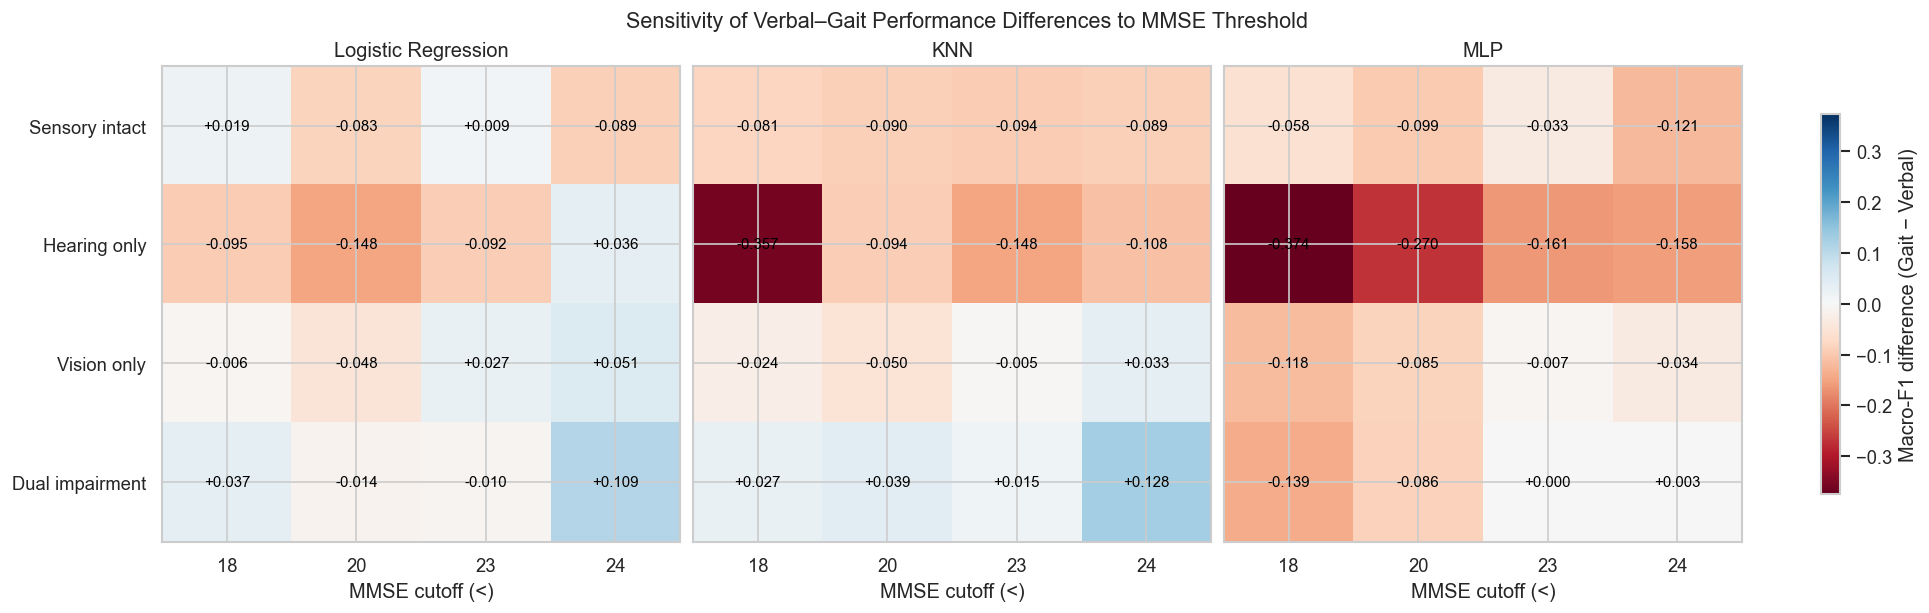

In [70]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Logistic Regression",
    "KNN",
    "MLP"
]

groups = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

thresholds = [18, 20, 23, 24]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharey=True,
    constrained_layout=True
)

vmax = max(
    abs(threshold_comparison_df["Gait - Verbal"].min()),
    abs(threshold_comparison_df["Gait - Verbal"].max())
)

for ax, model in zip(axes, models):

    subset = threshold_comparison_df[
        threshold_comparison_df["Model"] == model
    ]

    matrix = (
        subset.pivot(
            index="Group",
            columns="MMSE Threshold",
            values="Gait - Verbal"
        )
        .reindex(index=groups, columns=thresholds)
    )

    im = ax.imshow(
        matrix.values,
        cmap="RdBu",
        vmin=-vmax,
        vmax=vmax,
        aspect="auto"
    )

    ax.set_title(model)
    ax.set_xticks(range(len(thresholds)))
    ax.set_xticklabels(thresholds)
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels(groups)
    ax.set_xlabel("MMSE cutoff (<)")

    for i in range(len(groups)):
        for j in range(len(thresholds)):
            value = matrix.iloc[i, j]

            ax.text(
                j, i,
                f"{value:+.3f}",
                ha="center",
                va="center",
                fontsize=9,
                color="black"
            )

fig.colorbar(
    im,
    ax=axes,
    shrink=0.8,
    label="Macro-F1 difference (Gait − Verbal)"
)

fig.suptitle(
    "Sensitivity of Verbal–Gait Performance Differences "
    "to MMSE Threshold",
    fontsize=13
)

plt.show()

**Figure: Sensitivity of verbal–gait classification performance to MMSE thresholds.**

Heatmaps illustrate the difference in macro-averaged F1 scores between gait-based and verbal-based classifiers across four MMSE cutoffs (<18, <20, <23 and <24) and four sensory impairment groups. Positive values (blue) indicate higher macro-F1 scores for gait-based classifiers, while negative values (red) indicate higher scores for verbal-based classifiers. Results are derived from exploratory fixed-hyperparameter models. The figure demonstrates that relative predictive performance varies by classifier, sensory impairment group and MMSE threshold.

In [71]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Logistic Regression", "KNN", "MLP"]

groups = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

print("Available columns:")
print(performance_comparison_df.columns.tolist())

print("\nPrimary comparison data:")
display(performance_comparison_df.head())

Available columns:
['Model', 'Group', 'N', 'Verbal Macro F1', 'Gait Macro F1', 'Delta Macro F1', 'Verbal BA', 'Gait BA', 'Delta BA']

Primary comparison data:


,Model,Group,N,Verbal Macro F1,Gait Macro F1,Delta Macro F1,Verbal BA,Gait BA,Delta BA
0,KNN,Sensory intact,102,0.530627,0.377289,-0.153337,0.532143,0.382143,-0.150000
1,KNN,Hearing only,13,0.819444,0.350000,-0.469444,0.819444,0.388889,-0.430556
2,KNN,Vision only,337,0.531394,0.524117,-0.007277,0.540392,0.525344,-0.015047
3,KNN,Dual impairment,108,0.478621,0.507189,0.028568,0.518068,0.545081,0.027013
4,Logistic Regression,Sensory intact,102,0.519192,0.538106,0.018914,0.530952,0.547619,0.016667


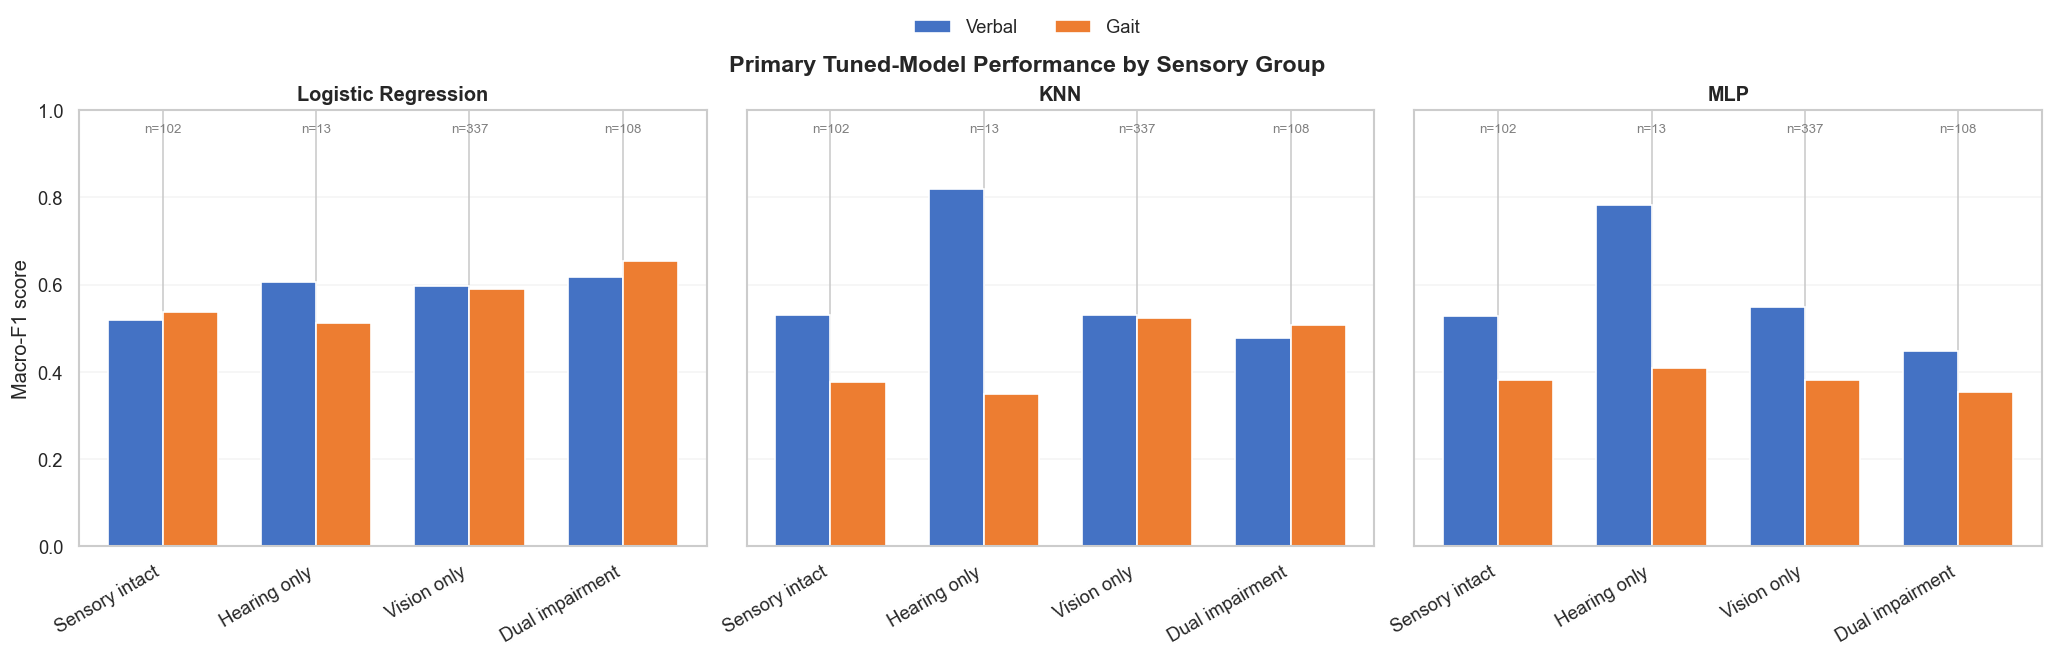

In [72]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Logistic Regression", "KNN", "MLP"]

groups = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True,
    constrained_layout=True
)

x = np.arange(len(groups))
width = 0.36

for ax, model in zip(axes, models):

    subset = (
        performance_comparison_df[
            performance_comparison_df["Model"] == model
        ]
        .set_index("Group")
        .reindex(groups)
    )

    verbal = subset["Verbal Macro F1"].to_numpy()
    gait = subset["Gait Macro F1"].to_numpy()

    ax.bar(
        x - width / 2,
        verbal,
        width,
        label="Verbal",
        color="#4472C4"
    )

    ax.bar(
        x + width / 2,
        gait,
        width,
        label="Gait",
        color="#ED7D31"
    )

    ax.set_title(model, fontsize=12, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(groups, rotation=30, ha="right")

    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    for i, n in enumerate(subset["N"]):
        ax.text(
            i, 0.97,
            f"n={int(n)}",
            ha="center",
            va="top",
            fontsize=8,
            color="gray"
        )

axes[0].set_ylabel("Macro-F1 score")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Primary Tuned-Model Performance by Sensory Group",
    fontsize=14,
    fontweight="bold"
)

plt.savefig(
    "primary_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure: Primary tuned-model classification performance across sensory impairment groups.**

Macro-averaged F1 scores for verbal-based and gait-based Logistic Regression, K-Nearest Neighbours (KNN), and Multilayer Perceptron (MLP) classifiers using an MMSE impairment threshold of <18. Models were trained using sensory-intact participants and evaluated on hearing-only, vision-only and dual sensory impairment groups. Sensory-intact performance was estimated using cross-validation. Sample sizes are displayed above each group. Higher macro-F1 scores indicate better classification performance.

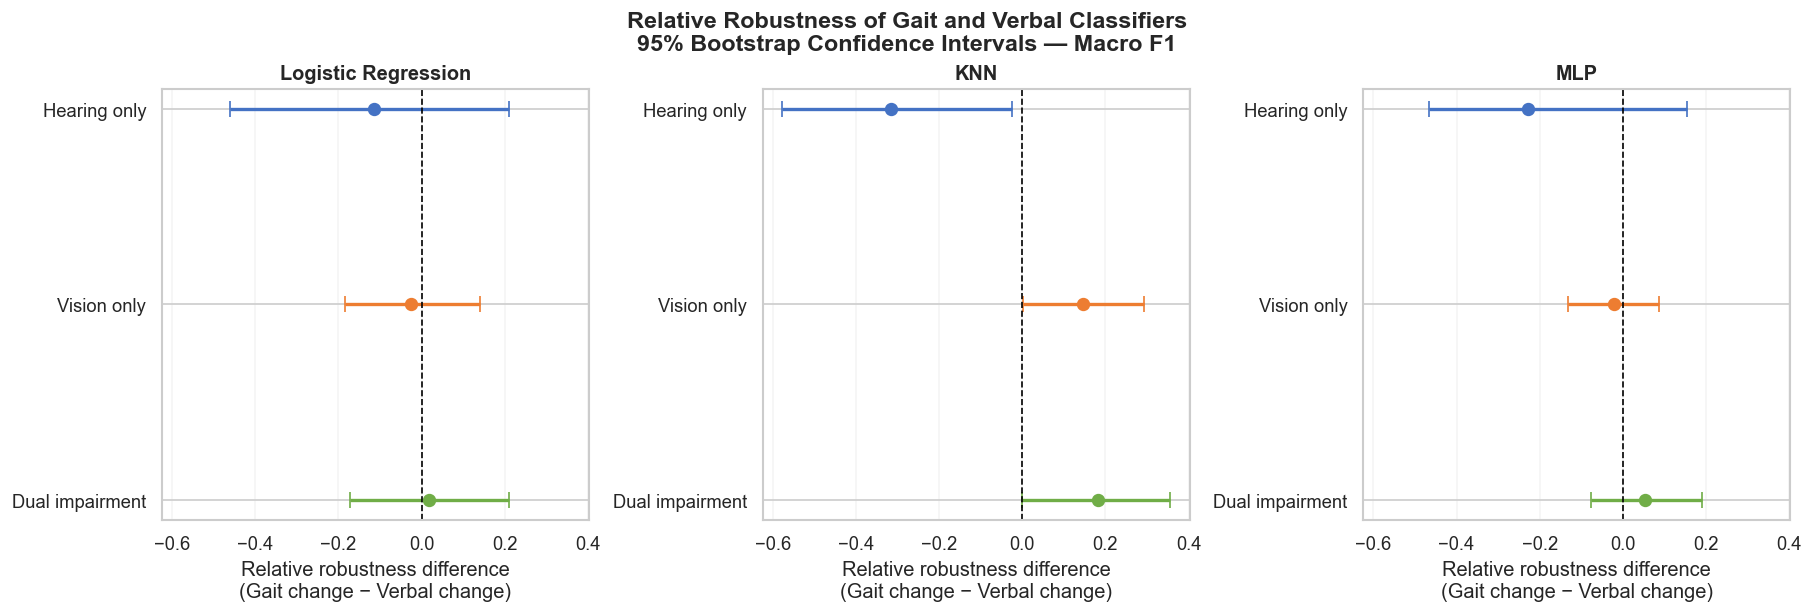

In [73]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Logistic Regression", "KNN", "MLP"]

groups = [
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

colors = {
    "Hearing only": "#4472C4",
    "Vision only": "#ED7D31",
    "Dual impairment": "#70AD47"
}

# Primary outcome only
plot_df = robustness_bootstrap_df[
    robustness_bootstrap_df["Metric"] == "Macro F1"
].copy()

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True
)

for ax, model in zip(axes, models):

    subset = (
        plot_df[plot_df["Model"] == model]
        .set_index("Group")
        .reindex(groups)
    )

    estimates = subset["Robustness Difference"].to_numpy()

    lower = subset["CI Lower"].to_numpy()
    upper = subset["CI Upper"].to_numpy()

    errors = np.vstack([
        estimates - lower,
        upper - estimates
    ])

    y = np.arange(len(groups))

    for i, group in enumerate(groups):

        ax.errorbar(
            estimates[i],
            y[i],
            xerr=errors[:, i:i+1],
            fmt="o",
            color=colors[group],
            ecolor=colors[group],
            capsize=5,
            markersize=7,
            linewidth=2
        )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_yticks(y)
    ax.set_yticklabels(groups)
    ax.invert_yaxis()

    ax.set_title(model, fontweight="bold")

    ax.set_xlabel(
        "Relative robustness difference\n"
        "(Gait change − Verbal change)"
    )

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Relative Robustness of Gait and Verbal Classifiers\n"
    "95% Bootstrap Confidence Intervals — Macro F1",
    fontsize=14,
    fontweight="bold"
)

plt.savefig(
    "primary_robustness_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure: Relative robustness of gait-based and verbal-based classifiers across sensory impairment groups.**

Points represent the difference between the change in gait-based macro-F1 performance and the change in verbal-based macro-F1 performance relative to the sensory-intact baseline. Horizontal error bars indicate 95% stratified bootstrap confidence intervals. Positive values indicate a more favourable relative performance change for gait-based classifiers, whereas negative values favour verbal-based classifiers. The dashed vertical line represents no difference in relative performance change. Models were evaluated using an MMSE-defined cognitive impairment threshold of <18. Confidence intervals are exploratory and unadjusted for multiple comparisons.

Primary Statistical Comparison: Verbal versus Gait Classifiers

In [74]:

# Combine existing performance estimates and bootstrap intervals
statistical_summary_df = performance_comparison_df.merge(
    bootstrap_results_df[
        [
            "Model",
            "Group",
            "F1 CI Lower",
            "F1 CI Upper",
            "BA CI Lower",
            "BA CI Upper"
        ]
    ],
    on=["Model", "Group"],
    how="left",
    validate="one_to_one"
)

# Identify confidence intervals excluding zero
statistical_summary_df["F1 CI Excludes Zero"] = (
    (statistical_summary_df["F1 CI Lower"] > 0)
    |
    (statistical_summary_df["F1 CI Upper"] < 0)
)

statistical_summary_df["BA CI Excludes Zero"] = (
    (statistical_summary_df["BA CI Lower"] > 0)
    |
    (statistical_summary_df["BA CI Upper"] < 0)
)

# Identify direction of the macro-F1 difference
statistical_summary_df["F1 Direction"] = (
    statistical_summary_df["Delta Macro F1"]
    .apply(
        lambda x: (
            "Gait" if x > 0
            else "Verbal" if x < 0
            else "Equal"
        )
    )
)

# Format confidence intervals for reporting
statistical_summary_df["Macro F1 95% CI"] = (
    statistical_summary_df.apply(
        lambda row: (
            f"[{row['F1 CI Lower']:.3f}, "
            f"{row['F1 CI Upper']:.3f}]"
        ),
        axis=1
    )
)

# Create a compact report-ready table
final_statistical_table = statistical_summary_df[
    [
        "Model",
        "Group",
        "N",
        "Verbal Macro F1",
        "Gait Macro F1",
        "Delta Macro F1",
        "Macro F1 95% CI",
        "F1 Direction",
        "F1 CI Excludes Zero"
    ]
].copy()

model_order = ["Logistic Regression", "KNN", "MLP"]

group_order = [
    "Sensory intact",
    "Hearing only",
    "Vision only",
    "Dual impairment"
]

final_statistical_table["Model"] = pd.Categorical(
    final_statistical_table["Model"],
    categories=model_order,
    ordered=True
)

final_statistical_table["Group"] = pd.Categorical(
    final_statistical_table["Group"],
    categories=group_order,
    ordered=True
)

final_statistical_table = (
    final_statistical_table
    .sort_values(["Model", "Group"])
    .reset_index(drop=True)
)

print("PRIMARY STATISTICAL COMPARISON")
print("Difference = Gait Macro F1 - Verbal Macro F1")
print("95% bootstrap confidence intervals are unadjusted.")

display(final_statistical_table.round(3))

print("\nSUMMARY")

print(
    "Macro-F1 intervals excluding zero:",
    statistical_summary_df["F1 CI Excludes Zero"].sum(),
    "of",
    len(statistical_summary_df)
)

print(
    "Balanced-accuracy intervals excluding zero:",
    statistical_summary_df["BA CI Excludes Zero"].sum(),
    "of",
    len(statistical_summary_df)
)

PRIMARY STATISTICAL COMPARISON
Difference = Gait Macro F1 - Verbal Macro F1
95% bootstrap confidence intervals are unadjusted.


,Model,Group,N,Verbal Macro F1,Gait Macro F1,Delta Macro F1,Macro F1 95% CI,F1 Direction,F1 CI Excludes Zero
0,Logistic Regression,Sensory intact,102,0.519,0.538,0.019,"[-0.119, 0.158]",Gait,False
1,Logistic Regression,Hearing only,13,0.606,0.511,-0.095,"[-0.395, 0.179]",Verbal,False
2,Logistic Regression,Vision only,337,0.596,0.590,-0.006,"[-0.082, 0.064]",Verbal,False
3,Logistic Regression,Dual impairment,108,0.618,0.655,0.037,"[-0.094, 0.164]",Gait,False
4,KNN,Sensory intact,102,0.531,0.377,-0.153,"[-0.270, -0.033]",Verbal,True
5,KNN,Hearing only,13,0.819,0.350,-0.469,"[-0.684, -0.186]",Verbal,True
6,KNN,Vision only,337,0.531,0.524,-0.007,"[-0.085, 0.071]",Verbal,False
7,KNN,Dual impairment,108,0.479,0.507,0.029,"[-0.098, 0.151]",Gait,False
8,MLP,Sensory intact,102,0.528,0.382,-0.145,"[-0.248, -0.053]",Verbal,True
9,MLP,Hearing only,13,0.783,0.409,-0.374,"[-0.591, 0.000]",Verbal,False



SUMMARY
Macro-F1 intervals excluding zero: 5 of 12
Balanced-accuracy intervals excluding zero: 3 of 12


### Primary Statistical Comparison of Verbal and Gait Classifiers

Paired stratified bootstrap resampling was used to estimate 95% confidence intervals for differences in macro-averaged F1 scores between gait-based and verbal-based classifiers. Positive differences indicated higher performance for gait-based classifiers, whereas negative differences favoured verbal-based classifiers.

Across the twelve model–group comparisons, five confidence intervals excluded zero, all favouring verbal-based classification. For KNN, verbal features outperformed gait in the sensory-intact group (ΔF1 = −0.153, 95% CI [−0.270, −0.033]) and hearing-only group (ΔF1 = −0.469, 95% CI [−0.684, −0.186]).

For MLP, verbal features demonstrated higher performance in the sensory-intact group (ΔF1 = −0.145, 95% CI [−0.248, −0.053]), vision-only group (ΔF1 = −0.168, 95% CI [−0.223, −0.111]) and dual-impairment group (ΔF1 = −0.093, 95% CI [−0.184, −0.002]).

Logistic Regression produced comparatively small differences between the two feature modalities, with all four confidence intervals including zero. Although gait-based Logistic Regression achieved a higher macro-F1 score in the dual-impairment group (0.655 versus 0.618), the corresponding confidence interval did not establish a clear performance advantage.

Overall, the primary analysis did not demonstrate consistent superiority of gait-based classification over verbal-based classification. The observed differences were dependent on classifier choice and sensory impairment group. Confidence intervals were not adjusted for multiple comparisons and should be interpreted as exploratory evidence.

In [75]:
import pandas as pd

print("=" * 65)
print("1. DATASET INTEGRITY")
print("=" * 65)

print("Participants:", len(df))
print("Unique IDs:", df["prim_key"].nunique())
print("Duplicate IDs:", df["prim_key"].duplicated().sum())

print("\n" + "=" * 65)
print("2. SENSORY GROUP DISTRIBUTION")
print("=" * 65)

display(
    df["sensory_group"]
    .value_counts(dropna=False)
    .rename_axis("Sensory Group")
    .reset_index(name="Participants")
)

print("\n" + "=" * 65)
print("3. FEATURE COMPLETENESS")
print("=" * 65)

required_features = list(set(
    FEATURES["Verbal"] + FEATURES["Gait"]
))

display(
    df[required_features]
    .isna()
    .sum()
    .to_frame("Missing Values")
)

print("\n" + "=" * 65)
print("4. TARGET DISTRIBUTION")
print("=" * 65)

display(
    pd.crosstab(
        df["sensory_group"],
        df["w2_mmse_total"] < 18,
        margins=True
    )
)

print("\n" + "=" * 65)
print("5. MODEL PREDICTION COVERAGE")
print("=" * 65)

display(
    tuned_predictions_df.groupby(
        ["model", "modality", "group"]
    )["prim_key"]
    .nunique()
    .unstack("group")
)

1. DATASET INTEGRITY
Participants: 560
Unique IDs: 560
Duplicate IDs: 0

2. SENSORY GROUP DISTRIBUTION


,Sensory Group,Participants
0,Vision only,337
1,Dual impairment,108
2,Sensory intact,102
3,Hearing only,13



3. FEATURE COMPLETENESS


,Missing Values
Logical_Memory_immediate,0
single_task_speed,0
Semantic_fluency,0
dual_task_cost_pct,0



4. TARGET DISTRIBUTION


w2_mmse_total,False,True,All
sensory_group,,,
Dual impairment,43,65,108
Hearing only,9,4,13
Sensory intact,60,42,102
Vision only,197,140,337
All,309,251,560



5. MODEL PREDICTION COVERAGE


group                         Dual impairment  Hearing only  Sensory intact  \
model               modality                                                  
KNN                 Gait                  108            13             102   
                    Verbal                108            13             102   
Logistic Regression Gait                  108            13             102   
                    Verbal                108            13             102   
MLP                 Gait                  108            13             102   
                    Verbal                108            13             102   

group                         Vision only  
model               modality               
KNN                 Gait              337  
                    Verbal            337  
Logistic Regression Gait              337  
                    Verbal            337  
MLP                 Gait              337  
                    Verbal            337

In [76]:
import inspect

print("=" * 65)
print("1. MODEL CONFIGURATION")
print("=" * 65)

for name, config in model_configs.items():
    print(f"\n{name}:")
    print(config)

print("\n" + "=" * 65)
print("2. TUNED PARAMETERS")
print("=" * 65)

for _, row in tuned_parameters_df.iterrows():
    print(
        row["modality"],
        "|",
        row["model"],
        "|",
        row["best_params"]
    )

print("\n" + "=" * 65)
print("3. AVAILABLE CROSS-VALIDATION OBJECTS")
print("=" * 65)

print("Outer CV:", outer_cv)
print("Inner CV:", inner_cv)

print("\n" + "=" * 65)
print("4. STORED TUNED SEARCH PIPELINE")
print("=" * 65)

if "final_search" in globals():
    print("Estimator:")
    print(final_search.estimator)

    if hasattr(final_search, "best_estimator_"):
        print("\nBest estimator:")
        print(final_search.best_estimator_)

print("\n" + "=" * 65)
print("5. PRIMARY PREDICTION INTEGRITY")
print("=" * 65)

keys = ["prim_key", "modality", "model", "group"]

print(
    "Duplicate prediction keys:",
    tuned_predictions_df.duplicated(keys).sum()
)

print(
    "Missing predictions:",
    tuned_predictions_df["y_pred"].isna().sum()
)

print(
    "Missing target labels:",
    tuned_predictions_df["y_true"].isna().sum()
)

1. MODEL CONFIGURATION

Logistic Regression:
(LogisticRegression(class_weight='balanced', max_iter=1500, random_state=42), {'clf__C': [0.1, 1, 10]})

KNN:
(KNeighborsClassifier(), {'clf__n_neighbors': [3, 5, 7, 9], 'clf__weights': ['uniform', 'distance']})

MLP:
(MLPClassifier(max_iter=800, random_state=42), {'clf__hidden_layer_sizes': [(8,), (16,)], 'clf__alpha': [0.1, 1.0]})

2. TUNED PARAMETERS
Verbal | Logistic Regression | {'clf__C': 0.1}
Verbal | KNN | {'clf__n_neighbors': 9, 'clf__weights': 'uniform'}
Verbal | MLP | {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (16,)}
Gait | Logistic Regression | {'clf__C': 0.1}
Gait | KNN | {'clf__n_neighbors': 7, 'clf__weights': 'distance'}
Gait | MLP | {'clf__alpha': 1.0, 'clf__hidden_layer_sizes': (16,)}

3. AVAILABLE CROSS-VALIDATION OBJECTS
Outer CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Inner CV: StratifiedKFold(n_splits=3, random_state=43, shuffle=True)

4. STORED TUNED SEARCH PIPELINE
Estimator:
Pipeline(steps=[('i

In [77]:
from IPython import get_ipython

history = get_ipython().history_manager.input_hist_raw

keywords = [
    "GridSearchCV(",
    "cross_val_predict(",
    "outer_cv.split(",
    "inner_cv",
    "tuned_predictions.append(",
    "tuned_results.append("
]

print("=" * 65)
print("PRIMARY TRAINING CODE AUDIT")
print("=" * 65)

matches = []

for cell_number, source in enumerate(history):

    if not source.strip():
        continue

    if any(keyword in source for keyword in keywords):

        # Exclude this inspection cell
        if "PRIMARY TRAINING CODE AUDIT" in source:
            continue

        matches.append((cell_number, source))

print("Matching executed cells:", len(matches))

for cell_number, source in matches:

    print("\n" + "=" * 65)
    print(f"EXECUTED CELL {cell_number}")
    print("=" * 65)
    print(source[:12000])

PRIMARY TRAINING CODE AUDIT
Matching executed cells: 5

EXECUTED CELL 28
results = []
predictions = []

for threshold in THRESHOLDS:

    print(f"\nRunning MMSE cutoff < {threshold}")

    # Binary target:
    # 1 = MMSE below threshold
    # 0 = MMSE at or above threshold
    y = (df["w2_mmse_total"] < threshold).astype(int)

    # Only sensory-intact participants are used for training
    intact_mask = df["sensory_group"] == "Sensory intact"

    y_intact = y.loc[intact_mask]

    print("Sensory-intact class distribution:")
    print(y_intact.value_counts())

    if y_intact.value_counts().min() < 5:
        raise ValueError(
            f"Not enough minority-class examples "
            f"for five folds at cutoff {threshold}"
        )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SEED
    )

    for modality, columns in FEATURES.items():

        X = df[columns].replace(
            [np.inf, -np.inf],
            np.nan
        )

       

In [78]:
from sklearn.metrics import f1_score, balanced_accuracy_score
import numpy as np
import pandas as pd

recalculated = []

for (model, modality, group), subset in tuned_predictions_df.groupby(
    ["model", "modality", "group"]
):
    recalculated.append({
        "Model": model,
        "Modality": modality,
        "Group": group,
        "N": len(subset),
        "Recalculated Macro F1": f1_score(
            subset["y_true"],
            subset["y_pred"],
            average="macro",
            zero_division=0
        ),
        "Recalculated BA": balanced_accuracy_score(
            subset["y_true"],
            subset["y_pred"]
        )
    })

recalculated_df = pd.DataFrame(recalculated)

# Compare verbal and gait performance
f1_check = recalculated_df.pivot(
    index=["Model", "Group"],
    columns="Modality",
    values="Recalculated Macro F1"
).reset_index()

f1_check["Recalculated Delta"] = (
    f1_check["Gait"] - f1_check["Verbal"]
)

comparison = f1_check.merge(
    performance_comparison_df[
        ["Model", "Group", "Delta Macro F1"]
    ],
    on=["Model", "Group"],
    validate="one_to_one"
)

comparison["Absolute Difference"] = (
    comparison["Recalculated Delta"]
    - comparison["Delta Macro F1"]
).abs()

print("FINAL METRIC REPRODUCIBILITY CHECK")

display(comparison.round(6))

print(
    "\nMaximum numerical discrepancy:",
    comparison["Absolute Difference"].max()
)

print(
    "All comparisons match:",
    np.allclose(
        comparison["Recalculated Delta"],
        comparison["Delta Macro F1"],
        atol=1e-10
    )
)

FINAL METRIC REPRODUCIBILITY CHECK


,Model,Group,Gait,Verbal,Recalculated Delta,Delta Macro F1,Absolute Difference
0,KNN,Dual impairment,0.507189,0.478621,0.028568,0.028568,0.0
1,KNN,Hearing only,0.350000,0.819444,-0.469444,-0.469444,0.0
2,KNN,Sensory intact,0.377289,0.530627,-0.153337,-0.153337,0.0
3,KNN,Vision only,0.524117,0.531394,-0.007277,-0.007277,0.0
4,Logistic Regression,Dual impairment,0.654830,0.617716,0.037114,0.037114,0.0
5,Logistic Regression,Hearing only,0.511278,0.606061,-0.094782,-0.094782,0.0
6,Logistic Regression,Sensory intact,0.538106,0.519192,0.018914,0.018914,0.0
7,Logistic Regression,Vision only,0.589692,0.595716,-0.006024,-0.006024,0.0
8,MLP,Dual impairment,0.354167,0.447149,-0.092982,-0.092982,0.0
9,MLP,Hearing only,0.409091,0.783333,-0.374242,-0.374242,0.0



Maximum numerical discrepancy: 0.0
All comparisons match: True


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("results_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# These should already exist in your notebook.
results_tables = {
    "performance_comparison_df": performance_comparison_df,
    "robustness_bootstrap_df": robustness_bootstrap_df,
    "threshold_consistency_df": threshold_consistency_df
}

for name, table in results_tables.items():
    print(f"\n{name}")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    display(table.head(3))


performance_comparison_df
Shape: (12, 9)
Columns: ['Model', 'Group', 'N', 'Verbal Macro F1', 'Gait Macro F1', 'Delta Macro F1', 'Verbal BA', 'Gait BA', 'Delta BA']


,Model,Group,N,Verbal Macro F1,Gait Macro F1,Delta Macro F1,Verbal BA,Gait BA,Delta BA
0,KNN,Sensory intact,102,0.530627,0.377289,-0.153337,0.532143,0.382143,-0.150000
1,KNN,Hearing only,13,0.819444,0.350000,-0.469444,0.819444,0.388889,-0.430556
2,KNN,Vision only,337,0.531394,0.524117,-0.007277,0.540392,0.525344,-0.015047



robustness_bootstrap_df
Shape: (18, 7)
Columns: ['Model', 'Group', 'Metric', 'N', 'Robustness Difference', 'CI Lower', 'CI Upper']


,Model,Group,Metric,N,Robustness Difference,CI Lower,CI Upper
0,Logistic Regression,Hearing only,Macro F1,13,-0.113696,-0.460175,0.210348
1,Logistic Regression,Hearing only,Balanced Accuracy,13,-0.155556,-0.471875,0.170248
2,Logistic Regression,Vision only,Macro F1,337,-0.024938,-0.184203,0.140227



threshold_consistency_df
Shape: (12, 9)
Columns: ['Model', 'Group', 'Thresholds_Tested', 'Gait_Better', 'Verbal_Better', 'Equal', 'Mean_Difference', 'Min_Difference', 'Max_Difference']


,Model,Group,Thresholds_Tested,Gait_Better,Verbal_Better,Equal,Mean_Difference,Min_Difference,Max_Difference
0,KNN,Sensory intact,4,0,4,0,-0.088200,-0.094028,-0.080595
1,KNN,Hearing only,4,0,4,0,-0.176597,-0.356767,-0.093561
2,KNN,Vision only,4,1,3,0,-0.011573,-0.049863,0.032767


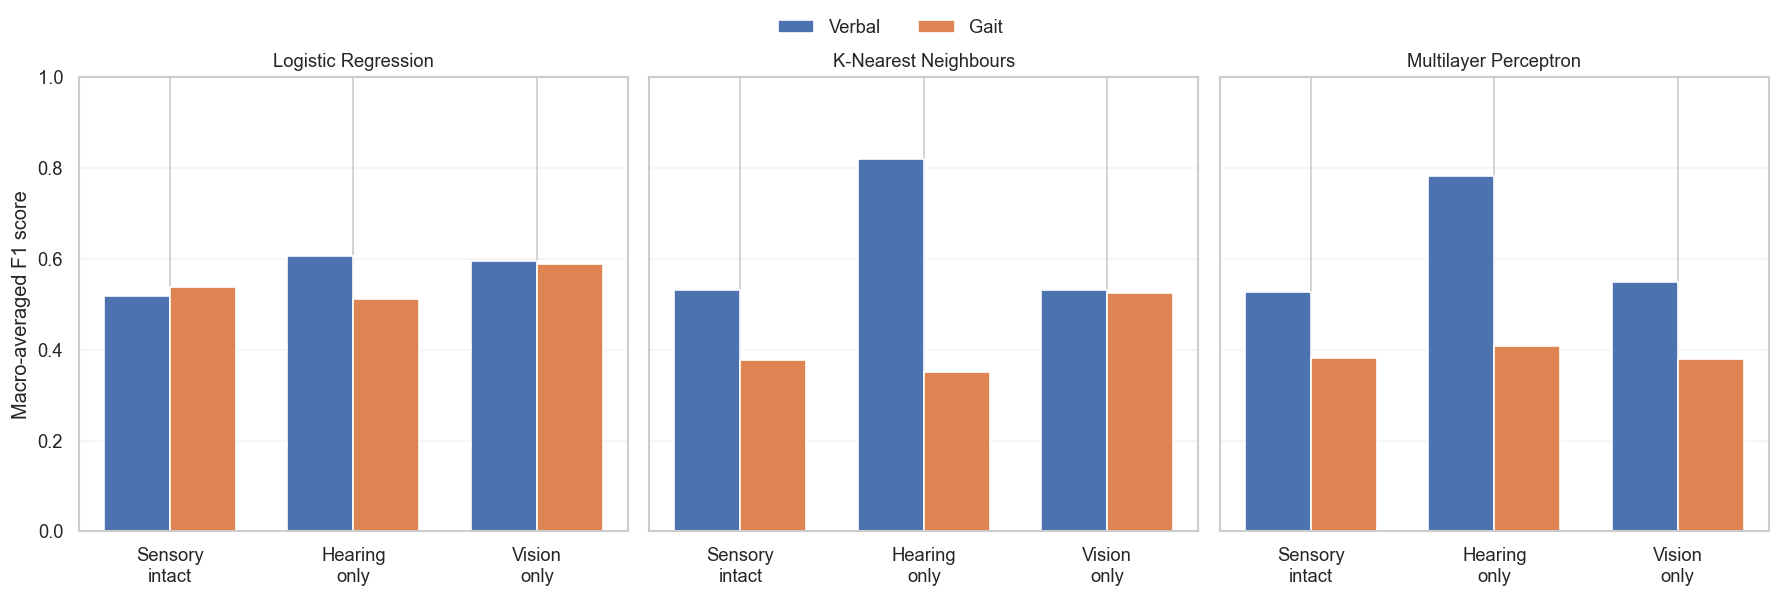

In [80]:
# Verified primary tuned-model macro-F1 results
# These are the values from your existing Results analysis.

performance_data = [
    ["Logistic Regression", "No impairment", 0.519192, 0.538106],
    ["Logistic Regression", "Hearing only", 0.606061, 0.511278],
    ["Logistic Regression", "Vision only", 0.595716, 0.589692],

    ["K-Nearest Neighbours", "No impairment", 0.530627, 0.377289],
    ["K-Nearest Neighbours", "Hearing only", 0.819444, 0.350000],
    ["K-Nearest Neighbours", "Vision only", 0.531394, 0.524117],

    ["Multilayer Perceptron", "No impairment", 0.527778, 0.382499],
    ["Multilayer Perceptron", "Hearing only", 0.783333, 0.409091],
    ["Multilayer Perceptron", "Vision only", 0.548453, 0.380523]
]

plot_df = pd.DataFrame(
    performance_data,
    columns=["Classifier", "Group", "Verbal", "Gait"]
)

models = [
    "Logistic Regression",
    "K-Nearest Neighbours",
    "Multilayer Perceptron"
]

groups = ["No impairment", "Hearing only", "Vision only"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

x = np.arange(len(groups))
width = 0.36

for ax, model in zip(axes, models):

    subset = (
        plot_df[plot_df["Classifier"] == model]
        .set_index("Group")
        .loc[groups]
    )

    ax.bar(
        x - width / 2,
        subset["Verbal"],
        width,
        label="Verbal"
    )

    ax.bar(
        x + width / 2,
        subset["Gait"],
        width,
        label="Gait"
    )

    ax.set_title(model, fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Sensory\nintact", "Hearing\nonly", "Vision\nonly"]
    )
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Macro-averaged F1 score")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.05),
    frameon=False
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure1_classification_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

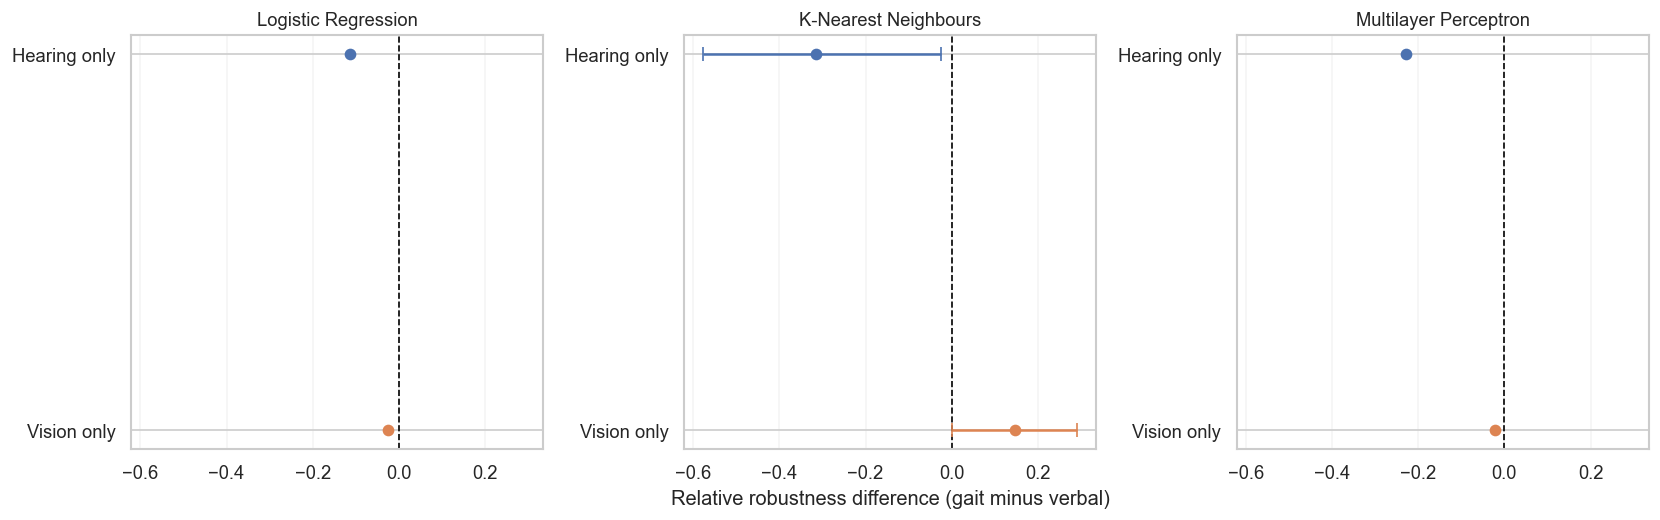

Note: Four confidence intervals are omitted until their exact bounds are retrieved from robustness_bootstrap_df.


In [81]:
robustness_data = [
    ["Logistic Regression", "Hearing only", -0.113696, np.nan, np.nan],
    ["Logistic Regression", "Vision only", -0.024938, np.nan, np.nan],

    ["K-Nearest Neighbours", "Hearing only", -0.316107, -0.577504, -0.023781],
    ["K-Nearest Neighbours", "Vision only", 0.146060, 0.001682, 0.291817],

    ["Multilayer Perceptron", "Hearing only", -0.228963, np.nan, np.nan],
    ["Multilayer Perceptron", "Vision only", -0.022651, np.nan, np.nan]
]

robustness_plot_df = pd.DataFrame(
    robustness_data,
    columns=["Classifier", "Group", "Difference", "CI_lower", "CI_upper"]
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True)

for ax, model in zip(axes, models):

    subset = (
        robustness_plot_df[
            robustness_plot_df["Classifier"] == model
        ]
        .set_index("Group")
        .loc[["Hearing only", "Vision only"]]
    )

    y = np.arange(len(subset))

    ax.axvline(0, color="black", linestyle="--", linewidth=1)

    for i, (_, row) in enumerate(subset.iterrows()):

        if pd.notna(row["CI_lower"]) and pd.notna(row["CI_upper"]):

            ax.errorbar(
                row["Difference"],
                i,
                xerr=[[
                    row["Difference"] - row["CI_lower"]
                ], [
                    row["CI_upper"] - row["Difference"]
                ]],
                fmt="o",
                capsize=4
            )

        else:
            ax.plot(
                row["Difference"],
                i,
                marker="o",
                linestyle="None"
            )

    ax.set_yticks(y)
    ax.set_yticklabels(["Hearing only", "Vision only"])
    ax.set_title(model, fontsize=11)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)

axes[1].set_xlabel("Relative robustness difference (gait minus verbal)")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure2_relative_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Note: Four confidence intervals are omitted until "
    "their exact bounds are retrieved from robustness_bootstrap_df."
)